# CSV 기상데이터: 기상 데이터 48개 열의 EDA

시점(입항 전(2),접안 전(2),입항시(2), 접안시(2),접안기간(2)) **10개 분석 묶음**으로 나눴습니다. 각 묶음은 미리보기 → 통계 → 그래프의 별도 실행 셀로 구성됩니다.

총톤수·특보 유무·터미널로 제한하지 않고 **CSV 전체 행**을 분석합니다.

## 단위와 자료 해석

- `_mps`: m/s, `_m`: m, `_10m`: 값에 10을 곱하면 m, `_h`: 시간.
- 입항 전 24h 시정 `_m`은 원본 `_10m`에서 변환합니다. 다른 시정 열은 원래 `_10m` 단위를 유지합니다.
- 해구예측의 빈칸은 비특보 시점 등 자료 제공 조건 때문일 수도 있습니다. 빈칸을 맑음이나 파고 0으로 해석하지 않습니다.
- 해구우선 분석값은 관측과 예측이 섞여 있으므로 반드시 출처 빈도도 봅니다.
- 특보 정보는 같은 사건이 여러 선박에 반복될 수 있습니다. 여기의 건수는 독립적인 특보 사건 수가 아니라 **선박 행 기준**입니다.

## 1. CSV 읽기


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

# ===== 입력 파일·출력 폴더 =====
프로젝트폴더 = Path(r"C:\work\Port_Cast_Final")

파일 = (
    프로젝트폴더
    / "2.Data_Integrated Preprocessing"
    / "Data"
    / "port+weather_raw2.csv"
)

저장폴더 = (
    프로젝트폴더
    / "2.Data_Integrated Preprocessing"
    / "Output"
    / "CSV_기상_EDA_결과"
)

if not 파일.is_file():
    raise FileNotFoundError(f"CSV 파일이 없습니다: {파일}")

저장폴더.mkdir(parents=True, exist_ok=True)
그림그리기 = True  # 표만 필요하면 False로 바꾸세요.

print("읽는 파일:", 파일)
print("저장 폴더:", 저장폴더)

# ===== 한글 글꼴 설정 =====
if 그림그리기:
    import matplotlib.pyplot as plt
    from matplotlib import font_manager

    설치글꼴 = {
        글꼴.name
        for 글꼴 in font_manager.fontManager.ttflist
    }

    for 글꼴 in [
        "Malgun Gothic",
        "AppleGothic",
        "NanumGothic",
        "Noto Sans CJK KR",
    ]:
        if 글꼴 in 설치글꼴:
            plt.rcParams["font.family"] = 글꼴
            plt.rcParams["font.sans-serif"] = [글꼴]
            print("사용 폰트:", 글꼴)
            break
    else:
        print("한글 글꼴을 찾지 못했습니다. 글꼴 설치를 확인하세요.")

    plt.rcParams["axes.unicode_minus"] = False

# ===== CSV 읽기 =====
try:
    원본 = pd.read_csv(
        파일,
        encoding="utf-8-sig",
        low_memory=False,
    )
except UnicodeDecodeError:
    원본 = pd.read_csv(
        파일,
        encoding="cp949",
        low_memory=False,
    )

자료 = 원본.copy()

# 공백만 있는 칸도 빈값으로 처리
자료 = 자료.replace(r"^\s*$", pd.NA, regex=True)

print("행 수:", len(자료), "열 수:", len(자료.columns))
display(자료.head())


읽는 파일: C:\work\Port_Cast_Final\2.Data_Integrated Preprocessing\Data\port+weather_raw2.csv
저장 폴더: C:\work\Port_Cast_Final\2.Data_Integrated Preprocessing\Output\CSV_기상_EDA_결과
사용 폰트: Malgun Gothic
행 수: 36844 열 수: 62


,환적톤수,총톤수,선박명,입항일시,출항일시,양하톤수,터미널_선사,터미널,항만,터미널_Shift수량,...,접안시_해구예측풍속_mps,접안시_해구예측풍향_deg,접안시_해구예측매칭상태,접안시_해구우선_분석풍속_mps,접안시_해구우선_분석풍속출처,접안시_해구우선_분석유의파고_m,접안시_해구우선_분석유의파고출처,입항전24h_특보노출시간_h,접안전24h_특보노출시간_h,입항부터접안_특보노출시간_h
0,11815.0,153115,MSC BARI,2022-09-02 20:22:00,2022-09-09 02:56:00,13745.0,MSC,PNIT,신항,0,...,NaN,NaN,특보중_예측표본없음,1.61,기존기상관측,0.9,기존기상관측,0.366667,0.583333,0.216667
1,1880.0,34610,PORT KLANG VOYAGER,2020-09-01 19:57:00,2020-09-05 01:18:00,12610.0,SKR,BPTC_G,북항,0,...,NaN,NaN,특보없음,1.60,기존기상관측,1.0,기존기상관측,0.000000,0.000000,NaN
2,22385.0,113042,SEASPAN BELIEF,2023-08-07 15:29:00,2023-08-12 06:00:00,31811.0,ONE,PNIT,신항,52,...,NaN,NaN,특보없음,4.05,기존기상관측,0.8,기존기상관측,0.000000,0.000000,0.000000
3,13652.0,141754,MAERSK ESMERALDAS,2023-08-08 03:10:00,2023-08-12 10:58:00,20933.0,MAE,PNC,신항,4,...,NaN,NaN,특보없음,1.30,기존기상관측,0.6,기존기상관측,0.000000,0.000000,0.000000
4,6667.0,75015,PRESIDENT TRUMAN,2021-08-22 08:00:00,2021-08-25 01:10:00,17972.0,APL,BNCT,신항,78,...,NaN,NaN,특보없음,1.38,기존기상관측,0.7,기존기상관측,17.000000,17.000000,0.000000


## 2. 요청한 열 이름과 단위 연결


In [2]:
# 요청한 이름과 원본 이름이 다른 두 열만 명시적으로 연결합니다.
# 원본 열은 지우거나 덮어쓰지 않습니다.
열연결정보 = []
요청시정 = "입항전_24h_시정최저_m"
원본시정 = "입항전_24h_시정최저_10m"
if 요청시정 not in 자료.columns and 원본시정 in 자료.columns:
    자료[요청시정] = pd.to_numeric(자료[원본시정], errors="coerce") * 10
    열연결정보.append({"분석열": 요청시정, "원본열": 원본시정, "처리": "10배하여 m로 변환"})

요청돌풍 = "접안전_24h_최대순간풍속_mps"
원본돌풍 = "접안전_24h_최대순간풍속최대_mps"
if 요청돌풍 not in 자료.columns and 원본돌풍 in 자료.columns:
    자료[요청돌풍] = 자료[원본돌풍]
    열연결정보.append({"분석열": 요청돌풍, "원본열": 원본돌풍, "처리": "같은 값을 요청한 이름으로 복사"})

display(pd.DataFrame(열연결정보))
pd.DataFrame(열연결정보).to_csv(저장폴더 / "00_열이름과단위연결.csv", index=False, encoding="utf-8-sig")


,분석열,원본열,처리
0,입항전_24h_시정최저_m,입항전_24h_시정최저_10m,10배하여 m로 변환
1,접안전_24h_최대순간풍속_mps,접안전_24h_최대순간풍속최대_mps,같은 값을 요청한 이름으로 복사


## 3.공통 분석 함수
숫자·범주·날짜를 구분하는 계산을 한 곳에 모았습니다.

In [3]:
# 함수는 반복해서 사용할 작업에 이름을 붙인 것입니다.
# 아래 함수들을 한 번 실행해 두면 10개 묶음에서 같은 기준으로 분석할 수 있습니다.

범주열 = {
    "입항시_풍향_8방위", "접안시_풍향_8방위",
    "입항시_특보종류구성_사건기준", "입항시_특보기간최고수준_사건기준",
    "입항시_해구우선_분석풍속출처", "입항시_해구우선_분석유의파고출처",
    "접안시_해구예측매칭상태", "접안시_해구우선_분석풍속출처", "접안시_해구우선_분석유의파고출처"
}
날짜열 = {"입항시_특보시작_KST", "입항시_특보종료_KST"}
통계이름 = ["평균", "중앙값", "P50", "P75", "P90", "P95", "최소값", "최대값"]
풍향허용값 = {"북", "북동", "동", "남동", "남", "남서", "서", "북서",
              "북풍", "북동풍", "동풍", "남동풍", "남풍", "남서풍", "서풍", "북서풍",
              "N", "NE", "E", "SE", "S", "SW", "W", "NW"}
전체요약 = []
전체빈도 = []
전체후보 = []

def 숫자로(열):
    값 = pd.to_numeric(자료[열], errors="coerce")
    return 값.replace([np.inf, -np.inf], np.nan)

def 범위위반(열, 값):
    # 풍속·파고·시정·노출시간은 음수가 될 수 없습니다.
    위반 = 값.lt(0)
    if 열.endswith("_deg"):
        위반 = 위반 | 값.ge(360)  # 풍향 각도는 0 이상 360 미만입니다.
    if 열 in ["입항전24h_특보노출시간_h", "접안전24h_특보노출시간_h"]:
        위반 = 위반 | 값.gt(24)
    if 열 == "입항부터접안_특보노출시간_h":
        입항 = pd.to_datetime(자료["입항일시"], format="mixed", errors="coerce")
        접안 = pd.to_datetime(자료["터미널_접안일시"], format="mixed", errors="coerce")
        대기_h = (접안 - 입항).dt.total_seconds() / 3600
        위반 = 위반 | (값.notna() & 대기_h.notna() & (대기_h.lt(0) | 값.gt(대기_h + 1e-6)))
    return 위반.fillna(False)

def 날짜순서위반():
    시작 = pd.to_datetime(자료["입항시_특보시작_KST"], format="mixed", errors="coerce")
    종료 = pd.to_datetime(자료["입항시_특보종료_KST"], format="mixed", errors="coerce")
    return 시작.notna() & 종료.notna() & 종료.lt(시작)

def 숫자통계(열):
    원래값 = 자료[열]
    변환값 = pd.to_numeric(원래값, errors="coerce")
    값 = 숫자로(열)
    유효 = 값.dropna()
    요약 = {
        "자료형": "숫자", "전체수": len(자료), "원본빈값수": int(원래값.isna().sum()),
        "결측표시문자수": 0, "결측치수": int(원래값.isna().sum()),
        "숫자변환실패수": int((원래값.notna() & 변환값.isna()).sum()),
        "무한값수": int(변환값.isin([np.inf, -np.inf]).sum()), "유효수": len(유효)
    }
    for 이름 in 통계이름:
        요약[이름] = np.nan
    if not 유효.empty:
        요약.update({"평균": 유효.mean(), "중앙값": 유효.median(),
                    "P50": 유효.quantile(0.50), "P75": 유효.quantile(0.75),
                    "P90": 유효.quantile(0.90), "P95": 유효.quantile(0.95),
                    "최소값": 유효.min(), "최대값": 유효.max()})

    물리위반 = 범위위반(열, 값)
    요약["물리범위위반수"] = int(물리위반.sum())
    요약["Q1"] = 유효.quantile(0.25) if len(유효) else np.nan
    요약["IQR"] = 유효.quantile(0.75) - 요약["Q1"] if len(유효) else np.nan
    요약["IQR하한"] = np.nan
    요약["IQR상한"] = np.nan
    요약["IQR후보수"] = np.nan
    IQR후보 = pd.Series(False, index=자료.index)
    요약["IQR판정"] = "표본 4개 미만 또는 IQR=0: 판정 보류"
    if 열.endswith("_deg"):
        요약["IQR판정"] = "풍향 각도: IQR 미적용"
        요약["원형평균_deg"] = np.nan
        방향 = 유효.loc[유효.ge(0) & 유효.lt(360)]
        if len(방향):
            라디안 = np.deg2rad(방향)
            x, y = np.cos(라디안).mean(), np.sin(라디안).mean()
            if np.hypot(x, y) > 1e-8:
                요약["원형평균_deg"] = np.rad2deg(np.arctan2(y, x)) % 360
    elif len(유효) >= 4 and 요약["IQR"] > 0:
        요약["IQR하한"] = 요약["Q1"] - 1.5 * 요약["IQR"]
        요약["IQR상한"] = 유효.quantile(0.75) + 1.5 * 요약["IQR"]
        IQR후보 = 값.lt(요약["IQR하한"]) | 값.gt(요약["IQR상한"])
        요약["IQR후보수"] = int(IQR후보.sum())
        요약["IQR판정"] = "1.5×IQR 적용"

    후보 = 물리위반 | IQR후보
    # IQR 계산을 보류했고 물리 위반도 없으면 '0개' 대신 미판정으로 표시합니다.
    요약["이상치후보수"] = int(후보.sum()) if (요약["IQR판정"] == "1.5×IQR 적용" or 열.endswith("_deg") or 후보.any()) else np.nan
    요약["판정설명"] = "후보는 오류로 확정하지 않으며 자동 삭제하지 않음"
    return 요약, 후보, IQR후보, 물리위반

def 범주통계(열):
    값 = 자료[열].astype("string").str.strip()
    명시결측 = 값.eq("결측").fillna(False)
    빈값 = 값.isna()
    요약 = {"자료형": "범주", "전체수": len(자료), "원본빈값수": int(빈값.sum()),
            "결측표시문자수": int(명시결측.sum()), "결측치수": int((빈값 | 명시결측).sum()),
            "유효수": int((~빈값 & ~명시결측).sum()), "숫자변환실패수": np.nan,
            "무한값수": np.nan, "IQR후보수": np.nan, "물리범위위반수": np.nan,
            "이상치후보수": np.nan, "IQR판정": "범주: IQR 미적용",
            "판정설명": "평균·백분위수는 해당 없음; 빈도표 사용"}
    후보 = pd.Series(False, index=자료.index)
    if "풍향_8방위" in 열:
        후보 = 값.notna() & ~값.isin(풍향허용값)
        요약["이상치후보수"] = int(후보.sum())
        요약["판정설명"] = "허용된 8방위 표현 외의 값만 점검 후보"
    빈도 = 값.fillna("(원본빈값)").value_counts(dropna=False).rename_axis("값").reset_index(name="건수")
    빈도["비율_pct"] = 빈도["건수"] / len(자료) * 100
    return 요약, 빈도, 후보

def 날짜통계(열):
    원래값 = 자료[열]
    값 = pd.to_datetime(원래값, format="mixed", errors="coerce")
    후보 = 날짜순서위반()
    요약 = {"자료형": "날짜", "전체수": len(자료), "원본빈값수": int(원래값.isna().sum()),
            "결측표시문자수": 0, "결측치수": int(원래값.isna().sum()), "유효수": int(값.notna().sum()),
            "날짜변환실패수": int((원래값.notna() & 값.isna()).sum()),
            "이상치후보수": int(후보.sum()), "IQR판정": "날짜: IQR 미적용",
            "판정설명": "종료가 시작보다 이른 기록을 후보로 표시; 평균은 미계산"}
    if 값.notna().any():
        요약.update({"중앙값": 값.median(), "P50": 값.quantile(0.5), "P75": 값.quantile(0.75),
                    "P90": 값.quantile(0.9), "P95": 값.quantile(0.95), "최소값": 값.min(), "최대값": 값.max()})
    return 요약, 후보

def 묶음분석(번호, 묶음이름, 열목록):
    결과 = []
    for 열 in 열목록:
        if 열 not in 자료.columns:
            raise KeyError(f"CSV에 필요한 열이 없습니다: {열}")
        IQR후보 = pd.Series(False, index=자료.index)
        물리위반 = pd.Series(False, index=자료.index)
        if 열 in 범주열:
            요약, 빈도, 후보 = 범주통계(열)
            빈도.insert(0, "열이름", 열)
            빈도.insert(0, "묶음", 묶음이름)
            전체빈도.append(빈도)
            print("범주별 건수:", 열)
            display(빈도)
        elif 열 in 날짜열:
            요약, 후보 = 날짜통계(열)
        else:
            요약, 후보, IQR후보, 물리위반 = 숫자통계(열)
        요약["열이름"] = 열
        요약["묶음"] = 묶음이름
        요약["결측률_pct"] = 요약["결측치수"] / len(자료) * 100
        결과.append(요약)
        전체요약.append(요약)
        if 후보.any():
            후보표 = pd.DataFrame({"CSV행번호": 자료.index[후보] + 2, "묶음": 묶음이름,
                                  "열이름": 열, "원래값": 자료.loc[후보, 열].to_numpy(),
                                  "IQR후보": IQR후보.loc[후보].to_numpy(),
                                  "물리범위위반": 물리위반.loc[후보].to_numpy(),
                                  "판정설명": 요약["판정설명"]})
            전체후보.append(후보표)
    표 = pd.DataFrame(결과)
    기본열 = ["열이름", "자료형", "전체수", "유효수", "결측치수", "결측률_pct", "원본빈값수", "결측표시문자수",
              "이상치후보수", "IQR후보수", "물리범위위반수", "숫자변환실패수", "날짜변환실패수", "무한값수"] + 통계이름
    표시열 = 기본열 + [열 for 열 in 표.columns if 열 not in 기본열]
    표 = 표.reindex(columns=표시열)
    표.to_csv(저장폴더 / f"{번호:02d}_{묶음이름}_통계.csv", index=False, encoding="utf-8-sig")
    with pd.option_context("display.max_rows", None, "display.max_columns", None):
        display(표)
    return 표

def 묶음그래프(번호, 묶음이름, 열목록):
    if not 그림그리기:
        return
    숫자열 = [열 for 열 in 열목록 if 열 not in 범주열 and 열 not in 날짜열]
    if 숫자열:
        그림, 축들 = plt.subplots(len(숫자열), 2, figsize=(13, 3.2 * len(숫자열)), squeeze=False)
        for i, 열 in enumerate(숫자열):
            값 = 숫자로(열).dropna()
            if len(값):
                축들[i, 0].hist(값, bins=30, color="#5E89AB", edgecolor="white")
                축들[i, 1].boxplot(값, orientation="horizontal")
            else:
                축들[i, 0].text(0.5, 0.5, "숫자 자료 없음", ha="center")
            축들[i, 0].set_title(열)
            축들[i, 0].set_ylabel("건수")
            축들[i, 1].set_title("상자그림: 점은 자동 오류 판정이 아님")
            축들[i, 0].set_xlabel("원래 단위의 값")
            축들[i, 1].set_xlabel("원래 단위의 값")
        그림.suptitle(묶음이름, y=1.01)
        그림.tight_layout()
        그림.savefig(저장폴더 / f"{번호:02d}_{묶음이름}_숫자분포.png", dpi=130, bbox_inches="tight")
        plt.show()
        plt.close(그림)
    for 열 in [열 for 열 in 열목록 if 열 in 범주열]:
        빈도 = 자료[열].astype("string").fillna("(원본빈값)").value_counts()
        그림, 축 = plt.subplots(figsize=(10, 4))
        빈도.plot.bar(ax=축, color="#5E89AB")
        축.set_title(열)
        축.set_ylabel("건수")
        축.tick_params(axis="x", rotation=35)
        그림.tight_layout()
        그림.savefig(저장폴더 / f"{번호:02d}_{열}_빈도.png", dpi=130)
        plt.show()
        plt.close(그림)
    for 열 in [열 for 열 in 열목록 if 열 in 날짜열]:
        날짜 = pd.to_datetime(자료[열], format="mixed", errors="coerce").dropna()
        if 날짜.empty:
            continue
        월별 = 날짜.dt.to_period("M").value_counts().sort_index()
        월별.index = 월별.index.astype(str)
        그림, 축 = plt.subplots(figsize=(13, 4))
        월별.plot.bar(ax=축, color="#5E89AB")
        축.set_title(열 + " 월별 기록 수 (같은 사건의 선박별 반복 포함)")
        축.set_ylabel("선박 기록 건수")
        그림.tight_layout()
        그림.savefig(저장폴더 / f"{번호:02d}_{열}_월별.png", dpi=130)
        plt.show()
        plt.close(그림)


---

## 1. 입항 시 기상

풍향은 현재 CSV에서 북·북동·동·남동·남·남서·서·북서로 기록되어 있습니다. 숫자와 구분하여 빈도표를 봅니다.

### A. 원래 값 미리보기


In [4]:
묶음1_열 = ['입항시_최대순간풍속_mps', '입항시_유의파고_m', '입항시_최대파고_m', '입항시_풍속_mps', '입항시_풍향_8방위', '입항시_시정_10m']
빠진열 = [열 for 열 in 묶음1_열 if 열 not in 자료.columns]
if 빠진열:
    raise KeyError(f"찾을 수 없는 열: {빠진열}")
display(자료[묶음1_열].head(10))


,입항시_최대순간풍속_mps,입항시_유의파고_m,입항시_최대파고_m,입항시_풍속_mps,입항시_풍향_8방위,입항시_시정_10m
0,2.63,0.9,1.2,1.61,동,401.0
1,3.55,1.0,1.4,1.60,북서,1436.0
2,6.32,0.8,1.1,4.05,북동,5000.0
3,1.92,0.6,0.8,1.30,북,5000.0
4,1.77,0.7,0.9,1.38,서,3634.0
5,1.89,0.5,0.8,1.41,남서,4994.0
6,11.35,0.8,1.0,8.44,남동,273.0
7,5.48,0.7,0.9,4.35,서,5000.0
8,4.29,1.3,1.6,3.35,남서,2732.0
9,0.97,0.5,0.7,0.77,남서,1931.0


### B. 결측·이상치 후보·통계

NaN인 통계는 해당 없음 또는 판정 보류입니다. 판정 설명을 함께 확인하세요.


In [5]:
묶음1_통계 = 묶음분석(1, '입항 시 기상', 묶음1_열)


범주별 건수: 입항시_풍향_8방위


,묶음,열이름,값,건수,비율_pct
0,입항 시 기상,입항시_풍향_8방위,북서,7064,19.172728
1,입항 시 기상,입항시_풍향_8방위,북,6063,16.455868
2,입항 시 기상,입항시_풍향_8방위,서,5188,14.08099
3,입항 시 기상,입항시_풍향_8방위,남,4485,12.172945
4,입항 시 기상,입항시_풍향_8방위,북동,4012,10.889154
5,입항 시 기상,입항시_풍향_8방위,남서,3706,10.058626
6,입항 시 기상,입항시_풍향_8방위,남동,3061,8.308001
7,입항 시 기상,입항시_풍향_8방위,동,2656,7.208772
8,입항 시 기상,입항시_풍향_8방위,(원본빈값),609,1.652915


,열이름,자료형,전체수,유효수,결측치수,결측률_pct,원본빈값수,결측표시문자수,이상치후보수,IQR후보수,물리범위위반수,숫자변환실패수,날짜변환실패수,무한값수,평균,중앙값,P50,P75,P90,P95,최소값,최대값,Q1,IQR,IQR하한,IQR상한,IQR판정,판정설명,묶음
0,입항시_최대순간풍속_mps,숫자,36844,35391,1453,3.943654,1453,0,467,467.0,0.0,0.0,NaN,0.0,3.143582,2.82,2.82,4.29,5.67,6.58,0.0,16.19,1.66,2.63,-2.285,8.235,1.5×IQR 적용,후보는 오류로 확정하지 않으며 자동 삭제하지 않음,입항 시 기상
1,입항시_유의파고_m,숫자,36844,32336,4508,12.235371,4508,0,2210,2210.0,0.0,0.0,NaN,0.0,0.504107,0.40,0.40,0.60,0.90,1.10,0.1,4.20,0.30,0.30,-0.150,1.050,1.5×IQR 적용,후보는 오류로 확정하지 않으며 자동 삭제하지 않음,입항 시 기상
2,입항시_최대파고_m,숫자,36844,32335,4509,12.238085,4509,0,1363,1363.0,0.0,0.0,NaN,0.0,0.688523,0.60,0.60,0.90,1.30,1.60,0.1,6.40,0.40,0.50,-0.350,1.650,1.5×IQR 적용,후보는 오류로 확정하지 않으며 자동 삭제하지 않음,입항 시 기상
3,입항시_풍속_mps,숫자,36844,36239,605,1.642058,605,0,796,796.0,0.0,0.0,NaN,0.0,2.155041,1.88,1.88,2.95,4.10,4.81,0.0,16.20,1.10,1.85,-1.675,5.725,1.5×IQR 적용,후보는 오류로 확정하지 않으며 자동 삭제하지 않음,입항 시 기상
4,입항시_풍향_8방위,범주,36844,36235,609,1.652915,609,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,범주: IQR 미적용,허용된 8방위 표현 외의 값만 점검 후보,입항 시 기상
5,입항시_시정_10m,숫자,36844,36734,110,0.298556,110,0,0,0.0,0.0,0.0,NaN,0.0,3273.777999,3486.50,3486.50,5000.00,5000.00,5000.00,14.0,5000.00,1919.00,3081.00,-2702.500,9621.500,1.5×IQR 적용,후보는 오류로 확정하지 않으며 자동 삭제하지 않음,입항 시 기상


### C. 분포와 빈도 그림

히스토그램은 값이 어느 구간에 모이는지, 상자그림은 중앙과 분포의 꼬리를 보여줍니다.


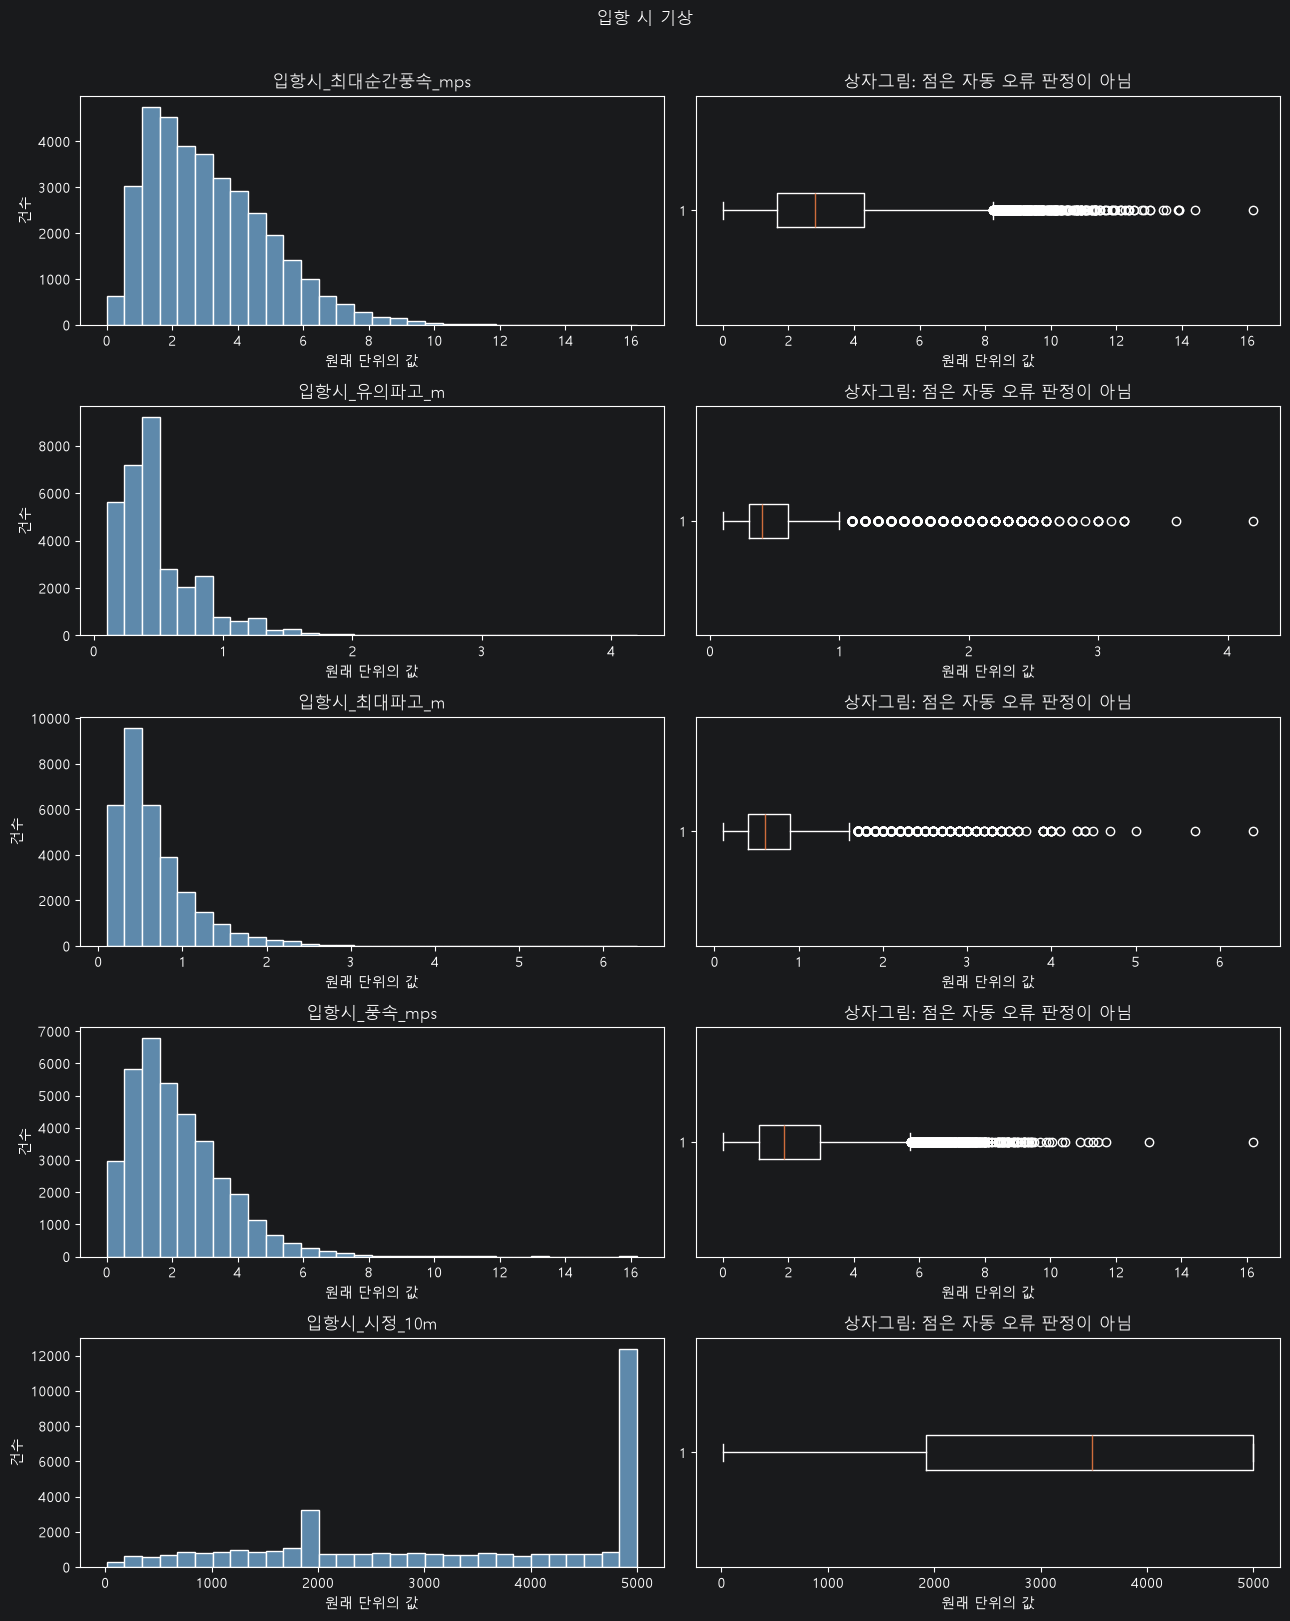

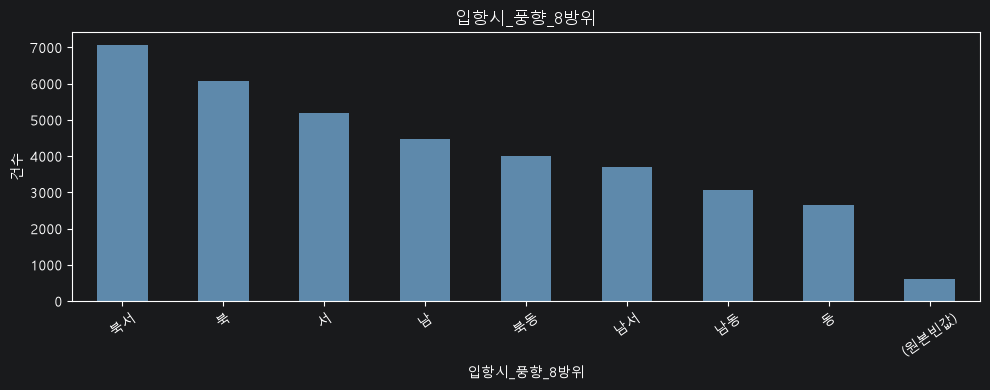

In [6]:
묶음그래프(1, '입항 시 기상', 묶음1_열)


---

## 2. 접안 시 기상

입항 시와 접안 시 값이 같을 수 있습니다. 같은 시간대의 관측값이 연결된 경우도 있으므로 동일하다는 이유로 삭제하지 않습니다.

### A. 원래 값 미리보기


In [7]:
묶음2_열 = ['접안시_최대순간풍속_mps', '접안시_유의파고_m', '접안시_최대파고_m', '접안시_풍속_mps', '접안시_풍향_8방위', '접안시_시정_10m']
빠진열 = [열 for 열 in 묶음2_열 if 열 not in 자료.columns]
if 빠진열:
    raise KeyError(f"찾을 수 없는 열: {빠진열}")
display(자료[묶음2_열].head(10))


,접안시_최대순간풍속_mps,접안시_유의파고_m,접안시_최대파고_m,접안시_풍속_mps,접안시_풍향_8방위,접안시_시정_10m
0,2.63,0.9,1.2,1.61,동,401.0
1,3.55,1.0,1.4,1.60,북서,1436.0
2,6.32,0.8,1.1,4.05,북동,5000.0
3,1.92,0.6,0.8,1.30,북,5000.0
4,1.77,0.7,0.9,1.38,서,3634.0
5,1.89,0.5,0.8,1.41,남서,4994.0
6,1.16,0.5,0.6,0.89,북서,3370.0
7,3.99,0.5,0.6,3.27,서,4756.0
8,4.29,1.3,1.6,3.35,남서,2732.0
9,0.97,0.5,0.7,0.77,남서,1931.0


### B. 결측·이상치 후보·통계

NaN인 통계는 해당 없음 또는 판정 보류입니다. 판정 설명을 함께 확인하세요.


In [8]:
묶음2_통계 = 묶음분석(2, '접안 시 기상', 묶음2_열)


범주별 건수: 접안시_풍향_8방위


,묶음,열이름,값,건수,비율_pct
0,접안 시 기상,접안시_풍향_8방위,북서,7038,19.10216
1,접안 시 기상,접안시_풍향_8방위,북,6157,16.710998
2,접안 시 기상,접안시_풍향_8방위,서,5143,13.958854
3,접안 시 기상,접안시_풍향_8방위,남,4415,11.982955
4,접안 시 기상,접안시_풍향_8방위,북동,4083,11.081859
5,접안 시 기상,접안시_풍향_8방위,남서,3714,10.080339
6,접안 시 기상,접안시_풍향_8방위,남동,3071,8.335143
7,접안 시 기상,접안시_풍향_8방위,동,2635,7.151775
8,접안 시 기상,접안시_풍향_8방위,(원본빈값),588,1.595918


,열이름,자료형,전체수,유효수,결측치수,결측률_pct,원본빈값수,결측표시문자수,이상치후보수,IQR후보수,물리범위위반수,숫자변환실패수,날짜변환실패수,무한값수,평균,중앙값,P50,P75,P90,P95,최소값,최대값,Q1,IQR,IQR하한,IQR상한,IQR판정,판정설명,묶음
0,접안시_최대순간풍속_mps,숫자,36844,35408,1436,3.897514,1436,0,473,473.0,0.0,0.0,NaN,0.0,3.136505,2.82,2.82,4.28,5.63,6.58,0.0,15.03,1.66,2.62,-2.27,8.21,1.5×IQR 적용,후보는 오류로 확정하지 않으며 자동 삭제하지 않음,접안 시 기상
1,접안시_유의파고_m,숫자,36844,32376,4468,12.126805,4468,0,2238,2238.0,0.0,0.0,NaN,0.0,0.504689,0.40,0.40,0.60,0.90,1.20,0.1,4.20,0.30,0.30,-0.15,1.05,1.5×IQR 적용,후보는 오류로 확정하지 않으며 자동 삭제하지 않음,접안 시 기상
2,접안시_최대파고_m,숫자,36844,32375,4469,12.129519,4469,0,1364,1364.0,0.0,0.0,NaN,0.0,0.689328,0.60,0.60,0.90,1.30,1.60,0.1,6.40,0.40,0.50,-0.35,1.65,1.5×IQR 적용,후보는 오류로 확정하지 않으며 자동 삭제하지 않음,접안 시 기상
3,접안시_풍속_mps,숫자,36844,36265,579,1.571491,579,0,828,828.0,0.0,0.0,NaN,0.0,2.150732,1.87,1.87,2.94,4.10,4.80,0.0,12.23,1.10,1.84,-1.66,5.70,1.5×IQR 적용,후보는 오류로 확정하지 않으며 자동 삭제하지 않음,접안 시 기상
4,접안시_풍향_8방위,범주,36844,36256,588,1.595918,588,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,범주: IQR 미적용,허용된 8방위 표현 외의 값만 점검 후보,접안 시 기상
5,접안시_시정_10m,숫자,36844,36764,80,0.217132,80,0,0,0.0,0.0,0.0,NaN,0.0,3268.604368,3473.50,3473.50,5000.00,5000.00,5000.00,16.0,5000.00,1920.00,3080.00,-2700.00,9620.00,1.5×IQR 적용,후보는 오류로 확정하지 않으며 자동 삭제하지 않음,접안 시 기상


### C. 분포와 빈도 그림

히스토그램은 값이 어느 구간에 모이는지, 상자그림은 중앙과 분포의 꼬리를 보여줍니다.


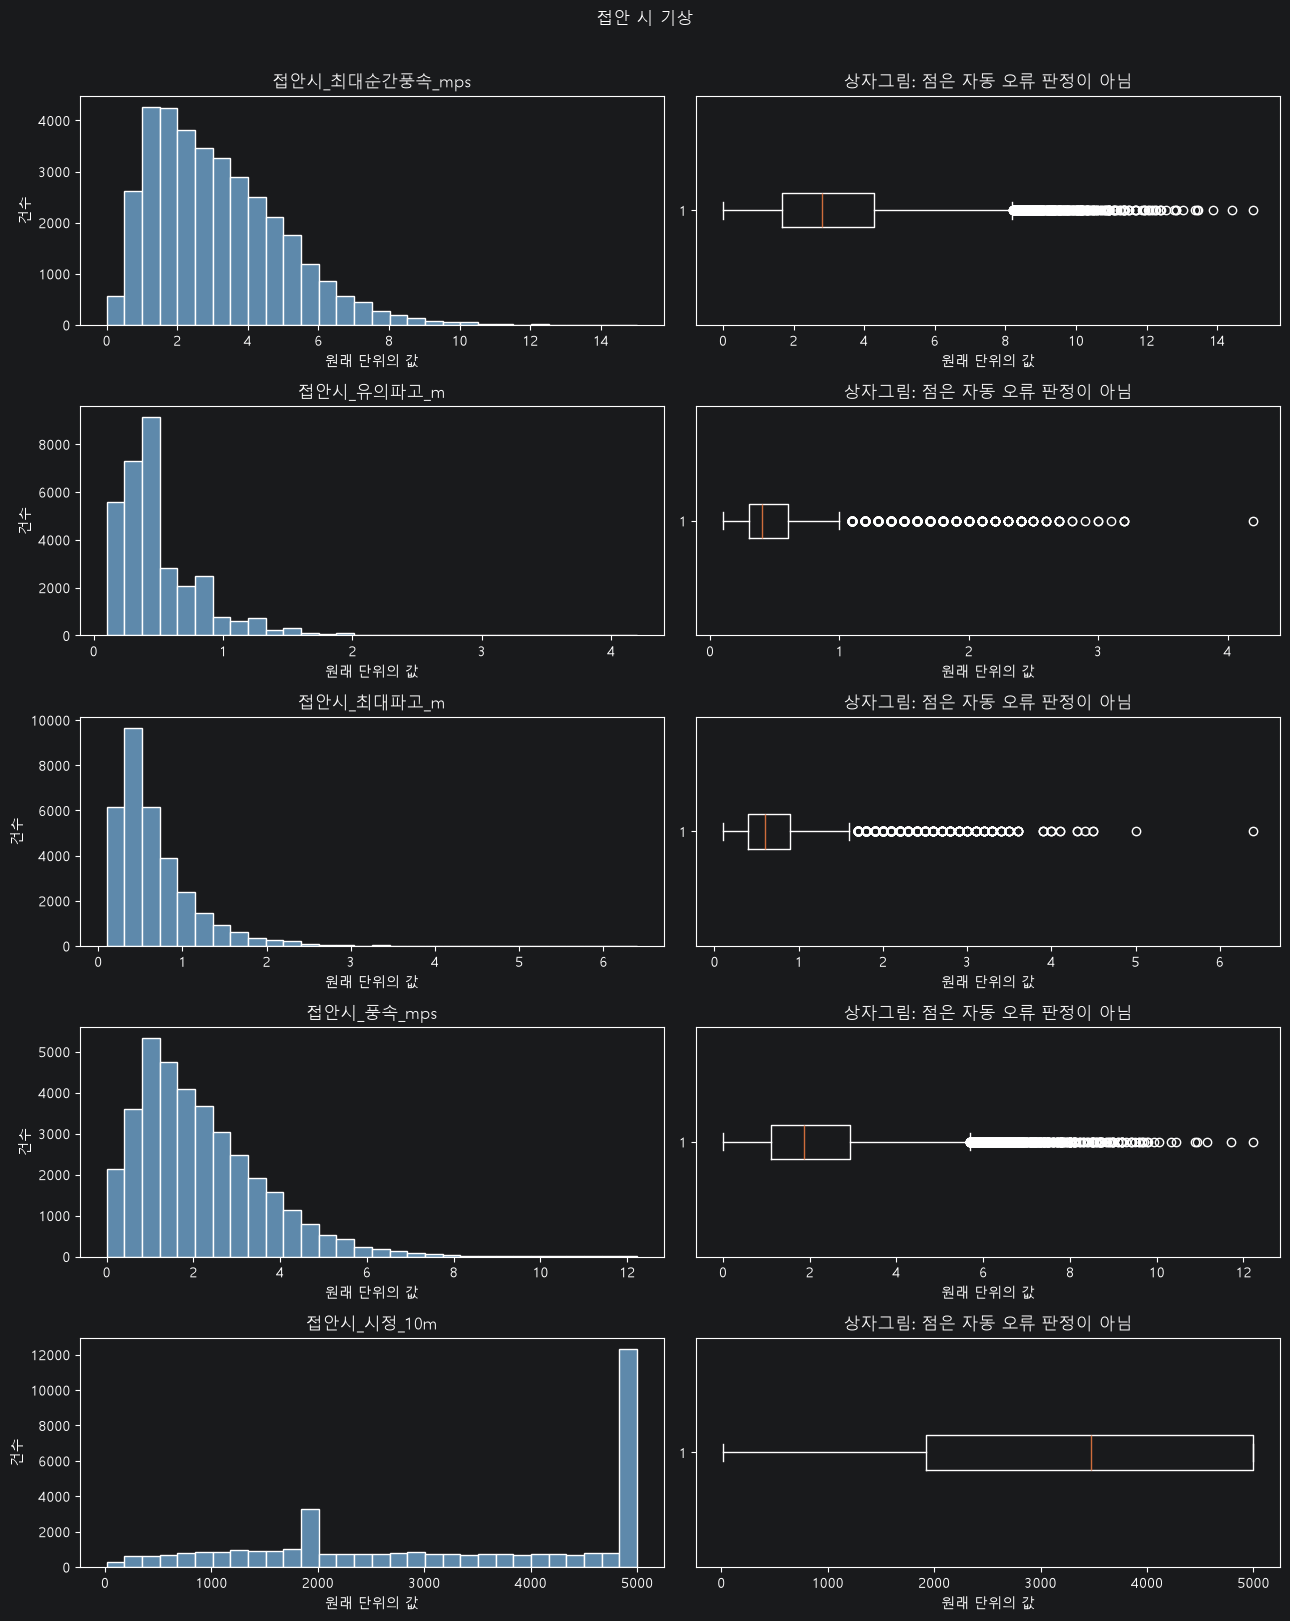

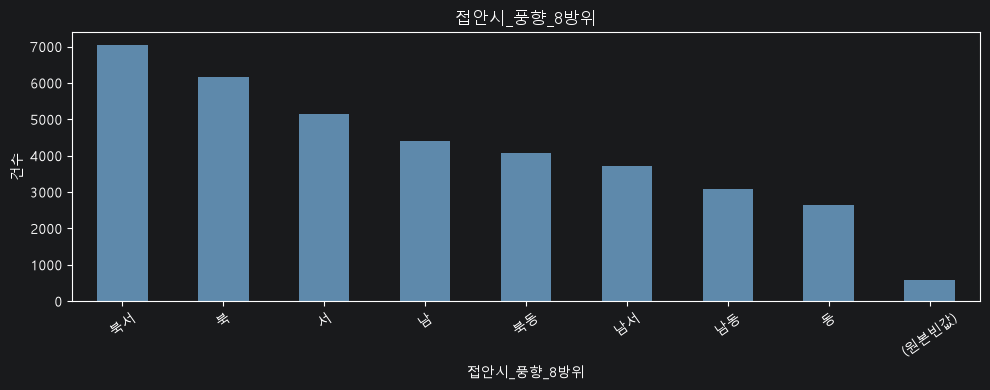

In [9]:
묶음그래프(2, '접안 시 기상', 묶음2_열)


---

## 3. 입항 전 24시간

입항 전 24시간의 최대·평균·최저값입니다. 입항 시 순간값과 같은 지표로 혼동하지 않습니다. 이 묶음의 시정은 요청에 맞춰 m로 바꿨습니다.

### A. 원래 값 미리보기


In [10]:
묶음3_열 = ['입항전_24h_최대순간풍속최대_mps', '입항전_24h_평균풍속_mps', '입항전_24h_유의파고최대_m', '입항전_24h_최대파고최대_m', '입항전_24h_시정최저_m']
빠진열 = [열 for 열 in 묶음3_열 if 열 not in 자료.columns]
if 빠진열:
    raise KeyError(f"찾을 수 없는 열: {빠진열}")
display(자료[묶음3_열].head(10))


,입항전_24h_최대순간풍속최대_mps,입항전_24h_평균풍속_mps,입항전_24h_유의파고최대_m,입항전_24h_최대파고최대_m,입항전_24h_시정최저_m
0,5.58,2.123750,1.1,1.3,3790.0
1,6.77,2.875000,1.6,2.3,17180.0
2,6.08,2.590833,0.7,0.8,50000.0
3,6.32,2.630000,0.8,1.1,48750.0
4,11.91,4.702917,1.4,1.9,990.0
5,7.67,3.278750,1.4,1.9,7120.0
6,9.95,3.853333,0.6,0.8,10530.0
7,5.06,2.050000,1.1,1.5,24180.0
8,11.91,5.245833,1.4,1.9,990.0
9,11.91,5.302917,1.4,1.9,990.0


### B. 결측·이상치 후보·통계

NaN인 통계는 해당 없음 또는 판정 보류입니다. 판정 설명을 함께 확인하세요.


In [11]:
묶음3_통계 = 묶음분석(3, '입항 전 24시간', 묶음3_열)


,열이름,자료형,전체수,유효수,결측치수,결측률_pct,원본빈값수,결측표시문자수,이상치후보수,IQR후보수,물리범위위반수,숫자변환실패수,날짜변환실패수,무한값수,평균,중앙값,P50,P75,P90,P95,최소값,최대값,Q1,IQR,IQR하한,IQR상한,IQR판정,판정설명,묶음
0,입항전_24h_최대순간풍속최대_mps,숫자,36844,35267,1577,4.280208,1577,0,1259,1259,0,0,NaN,0,5.893723,5.59,5.59,6.810000,8.260000,9.370000,1.20000,28.430000,4.62000,2.190000,1.335000,10.095000,1.5×IQR 적용,후보는 오류로 확정하지 않으며 자동 삭제하지 않음,입항 전 24시간
1,입항전_24h_평균풍속_mps,숫자,36844,36058,786,2.133319,786,0,1548,1548,0,0,NaN,0,2.181153,2.00,2.00,2.571979,3.295833,3.916667,0.28375,8.721667,1.58625,0.985729,0.107656,4.050573,1.5×IQR 적용,후보는 오류로 확정하지 않으며 자동 삭제하지 않음,입항 전 24시간
2,입항전_24h_유의파고최대_m,숫자,36844,32500,4344,11.790251,4344,0,1050,1050,0,0,NaN,0,0.783560,0.60,0.60,1.000000,1.400000,1.700000,0.10000,10.800000,0.40000,0.600000,-0.500000,1.900000,1.5×IQR 적용,후보는 오류로 확정하지 않으며 자동 삭제하지 않음,입항 전 24시간
3,입항전_24h_최대파고최대_m,숫자,36844,32500,4344,11.790251,4344,0,1406,1406,0,0,NaN,0,1.119745,0.90,0.90,1.400000,2.000000,2.500000,0.20000,17.200000,0.60000,0.800000,-0.600000,2.600000,1.5×IQR 적용,후보는 오류로 확정하지 않으며 자동 삭제하지 않음,입항 전 24시간
4,입항전_24h_시정최저_m,숫자,36844,36676,168,0.455977,168,0,0,0,0,0,NaN,0,19995.843603,16370.00,16370.00,30580.000000,46920.000000,50000.000000,110.00000,50000.000000,6950.00000,23630.000000,-28495.000000,66025.000000,1.5×IQR 적용,후보는 오류로 확정하지 않으며 자동 삭제하지 않음,입항 전 24시간


### C. 분포와 빈도 그림

히스토그램은 값이 어느 구간에 모이는지, 상자그림은 중앙과 분포의 꼬리를 보여줍니다.


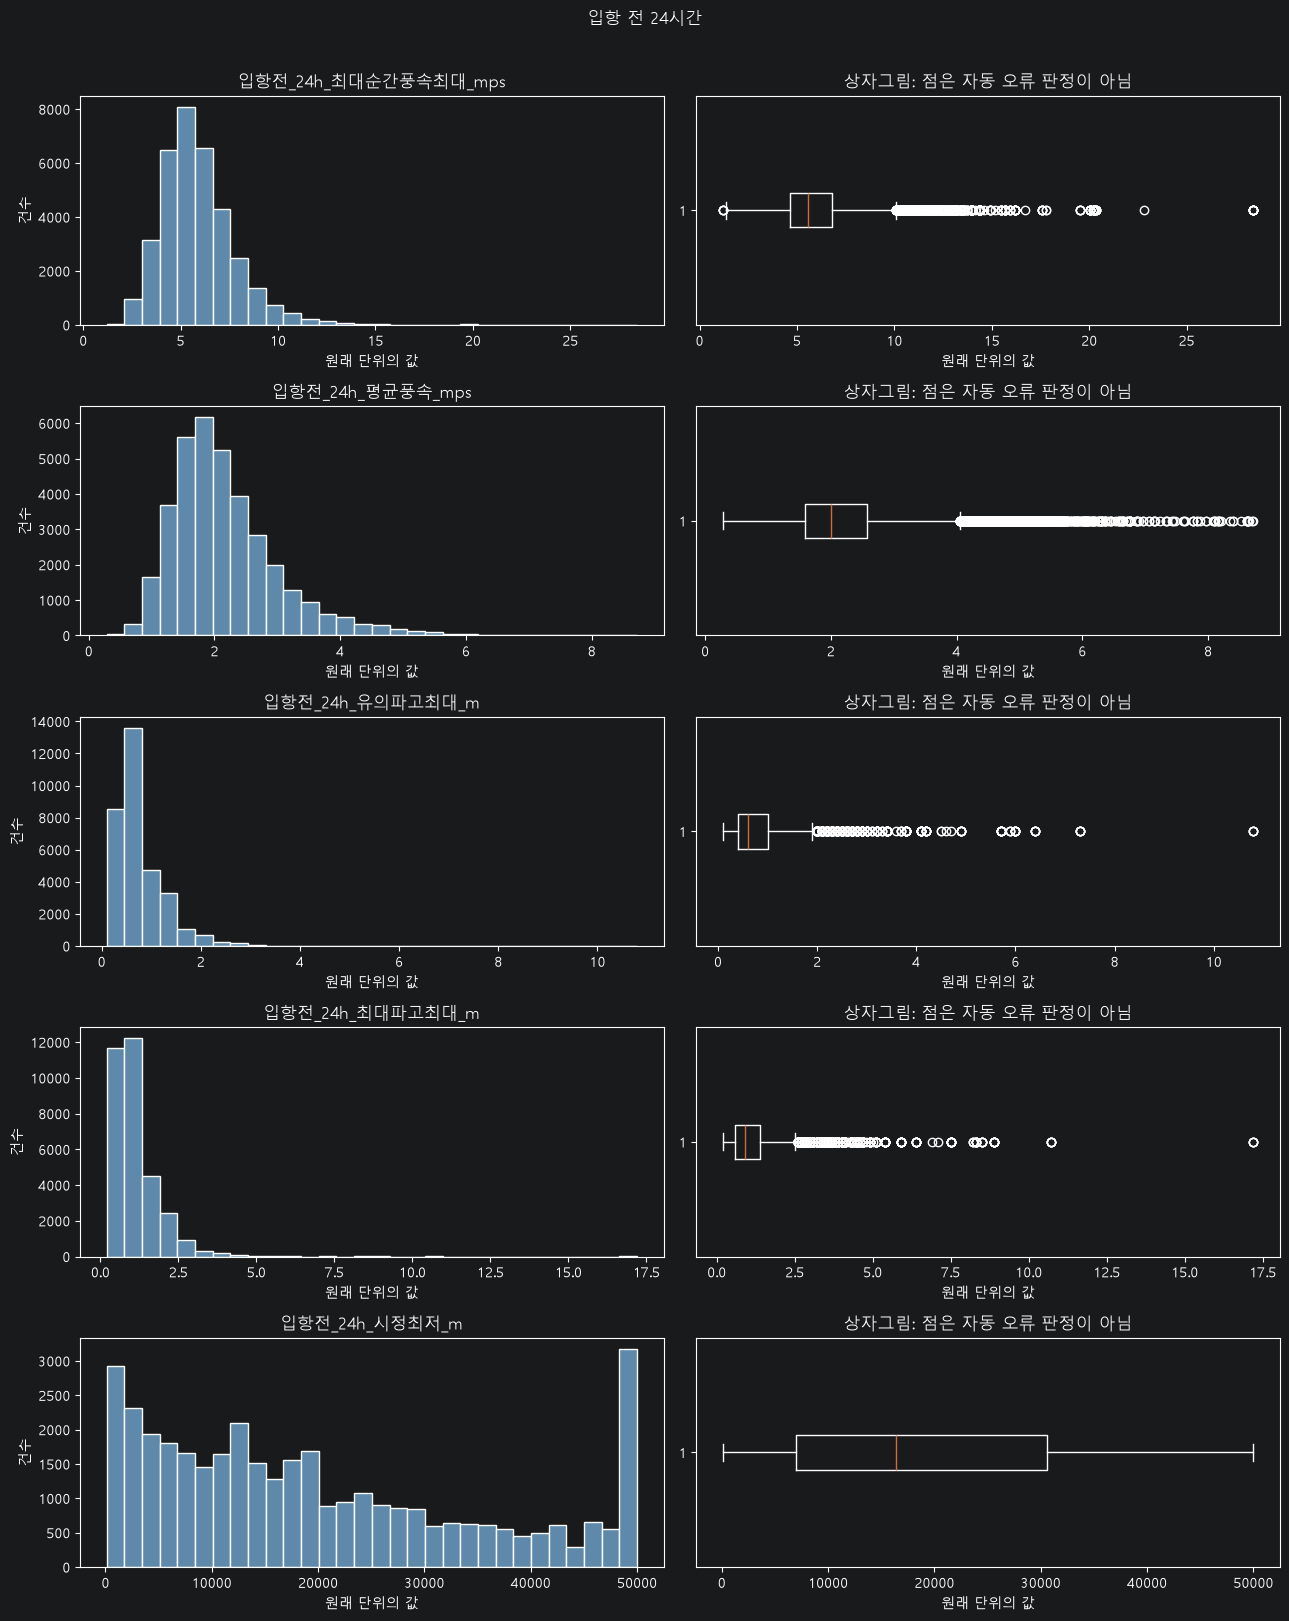

In [12]:
묶음그래프(3, '입항 전 24시간', 묶음3_열)


---

## 4. 접안 전 24시간

요청한 최대순간풍속 열은 실제 원본의 최대순간풍속최대 열에 연결했습니다. 이 묶음의 시정은 원래 10m 단위입니다.

### A. 원래 값 미리보기


In [13]:
묶음4_열 = ['접안전_24h_최대순간풍속_mps', '접안전_24h_평균풍속_mps', '접안전_24h_유의파고최대_m', '접안전_24h_최대파고최대_m', '접안전_24h_시정최저_10m']
빠진열 = [열 for 열 in 묶음4_열 if 열 not in 자료.columns]
if 빠진열:
    raise KeyError(f"찾을 수 없는 열: {빠진열}")
display(자료[묶음4_열].head(10))


,접안전_24h_최대순간풍속_mps,접안전_24h_평균풍속_mps,접안전_24h_유의파고최대_m,접안전_24h_최대파고최대_m,접안전_24h_시정최저_10m
0,5.58,2.123750,1.1,1.3,379.0
1,6.77,2.875000,1.6,2.3,1718.0
2,6.08,2.590833,0.7,0.8,5000.0
3,6.32,2.630000,0.8,1.1,4875.0
4,11.91,4.702917,1.4,1.9,99.0
5,7.67,3.278750,1.4,1.9,712.0
6,6.89,2.700833,0.9,1.4,1694.0
7,7.67,3.413750,1.4,1.9,597.0
8,11.91,5.245833,1.4,1.9,99.0
9,11.91,5.302917,1.4,1.9,99.0


### B. 결측·이상치 후보·통계

NaN인 통계는 해당 없음 또는 판정 보류입니다. 판정 설명을 함께 확인하세요.


In [14]:
묶음4_통계 = 묶음분석(4, '접안 전 24시간', 묶음4_열)


,열이름,자료형,전체수,유효수,결측치수,결측률_pct,원본빈값수,결측표시문자수,이상치후보수,IQR후보수,물리범위위반수,숫자변환실패수,날짜변환실패수,무한값수,평균,중앙값,P50,P75,P90,P95,최소값,최대값,Q1,IQR,IQR하한,IQR상한,IQR판정,판정설명,묶음
0,접안전_24h_최대순간풍속_mps,숫자,36844,35291,1553,4.215069,1553,0,1266,1266,0,0,NaN,0,5.889427,5.58,5.58,6.800000,8.250000,9.330000,1.20000,28.43000,4.620000,2.180000,1.350000,10.070000,1.5×IQR 적용,후보는 오류로 확정하지 않으며 자동 삭제하지 않음,접안 전 24시간
1,접안전_24h_평균풍속_mps,숫자,36844,36082,762,2.068179,762,0,1534,1534,0,0,NaN,0,2.179044,2.00,2.00,2.569583,3.283333,3.901229,0.28375,8.69125,1.585417,0.984167,0.109167,4.045833,1.5×IQR 적용,후보는 오류로 확정하지 않으며 자동 삭제하지 않음,접안 전 24시간
2,접안전_24h_유의파고최대_m,숫자,36844,32528,4316,11.714255,4316,0,1042,1042,0,0,NaN,0,0.782357,0.60,0.60,1.000000,1.400000,1.700000,0.10000,10.80000,0.400000,0.600000,-0.500000,1.900000,1.5×IQR 적용,후보는 오류로 확정하지 않으며 자동 삭제하지 않음,접안 전 24시간
3,접안전_24h_최대파고최대_m,숫자,36844,32528,4316,11.714255,4316,0,1391,1391,0,0,NaN,0,1.118310,0.90,0.90,1.400000,2.000000,2.500000,0.20000,17.20000,0.600000,0.800000,-0.600000,2.600000,1.5×IQR 적용,후보는 오류로 확정하지 않으며 자동 삭제하지 않음,접안 전 24시간
4,접안전_24h_시정최저_10m,숫자,36844,36711,133,0.360981,133,0,0,0,0,0,NaN,0,2002.522841,1637.00,1637.00,3062.000000,4705.000000,5000.000000,11.00000,5000.00000,698.000000,2364.000000,-2848.000000,6608.000000,1.5×IQR 적용,후보는 오류로 확정하지 않으며 자동 삭제하지 않음,접안 전 24시간


### C. 분포와 빈도 그림

히스토그램은 값이 어느 구간에 모이는지, 상자그림은 중앙과 분포의 꼬리를 보여줍니다.


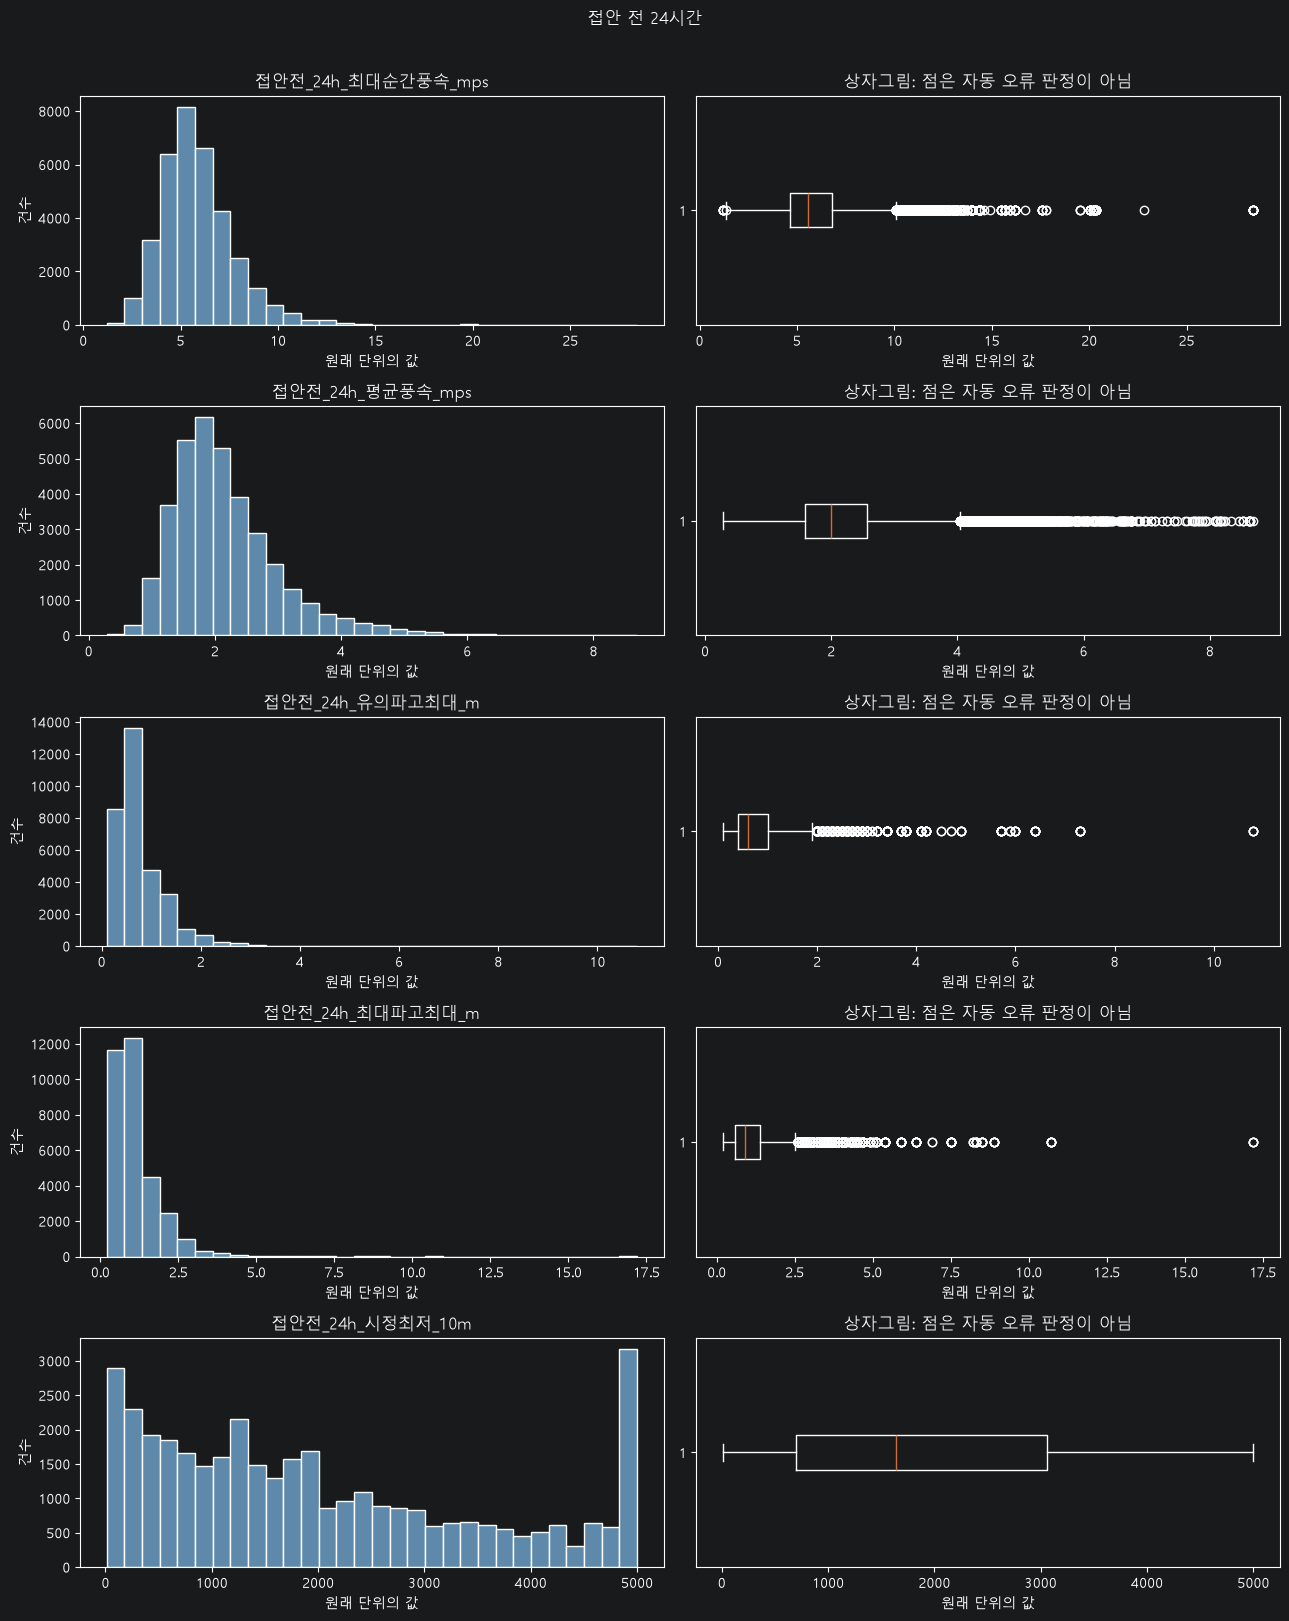

In [15]:
묶음그래프(4, '접안 전 24시간', 묶음4_열)


---

## 5. 접안 기간 기상

접안기간이 긴 선박은 큰 풍속·파고를 경험할 기회도 많습니다. 극값과 기간 사이의 관계를 곧바로 기상의 영향으로 해석하지 않습니다.

### A. 원래 값 미리보기


In [16]:
묶음5_열 = ['접안기간_순간풍속최대_mps', '접안기간_유의파고최대_m', '접안기간_풍속평균_mps', '접안기간_시정최저_10m']
빠진열 = [열 for 열 in 묶음5_열 if 열 not in 자료.columns]
if 빠진열:
    raise KeyError(f"찾을 수 없는 열: {빠진열}")
display(자료[묶음5_열].head(10))


,접안기간_순간풍속최대_mps,접안기간_유의파고최대_m,접안기간_풍속평균_mps,접안기간_시정최저_10m
0,22.79,4.9,3.208158,44.0
1,20.34,7.3,4.468354,139.0
2,20.25,4.1,3.813214,23.0
3,20.25,4.1,3.837115,23.0
4,20.18,2.9,3.236212,54.0
5,20.18,2.9,3.171379,54.0
6,20.18,2.9,3.320926,54.0
7,20.18,2.9,3.224138,54.0
8,20.18,2.9,3.106951,54.0
9,20.18,2.9,3.044730,54.0


### B. 결측·이상치 후보·통계

NaN인 통계는 해당 없음 또는 판정 보류입니다. 판정 설명을 함께 확인하세요.


In [17]:
묶음5_통계 = 묶음분석(5, '접안 기간 기상', 묶음5_열)


,열이름,자료형,전체수,유효수,결측치수,결측률_pct,원본빈값수,결측표시문자수,이상치후보수,IQR후보수,물리범위위반수,숫자변환실패수,날짜변환실패수,무한값수,평균,중앙값,P50,P75,P90,P95,최소값,최대값,Q1,IQR,IQR하한,IQR상한,IQR판정,판정설명,묶음
0,접안기간_순간풍속최대_mps,숫자,36844,35643,1201,3.259690,1201,0,1020,1020,0,0,NaN,0,5.617518,5.39000,5.39000,6.660000,8.090000,9.17000,0.25,22.79,4.320000,2.340000,0.810000,10.170000,1.5×IQR 적용,후보는 오류로 확정하지 않으며 자동 삭제하지 않음,접안 기간 기상
1,접안기간_유의파고최대_m,숫자,36844,32756,4088,11.095429,4088,0,1670,1670,0,0,NaN,0,0.743042,0.60000,0.60000,0.900000,1.300000,1.70000,0.10,10.80,0.400000,0.500000,-0.350000,1.650000,1.5×IQR 적용,후보는 오류로 확정하지 않으며 자동 삭제하지 않음,접안 기간 기상
2,접안기간_풍속평균_mps,숫자,36844,36643,201,0.545543,201,0,1257,1257,0,0,NaN,0,2.177369,2.01381,2.01381,2.628328,3.372444,3.96244,0.00,8.94,1.544444,1.083884,-0.081381,4.254154,1.5×IQR 적용,후보는 오류로 확정하지 않으며 자동 삭제하지 않음,접안 기간 기상
3,접안기간_시정최저_10m,숫자,36844,36831,13,0.035284,13,0,0,0,0,0,NaN,0,2119.214357,1776.00000,1776.00000,3303.000000,4869.000000,5000.00000,11.00,5000.00,774.000000,2529.000000,-3019.500000,7096.500000,1.5×IQR 적용,후보는 오류로 확정하지 않으며 자동 삭제하지 않음,접안 기간 기상


### C. 분포와 빈도 그림

히스토그램은 값이 어느 구간에 모이는지, 상자그림은 중앙과 분포의 꼬리를 보여줍니다.


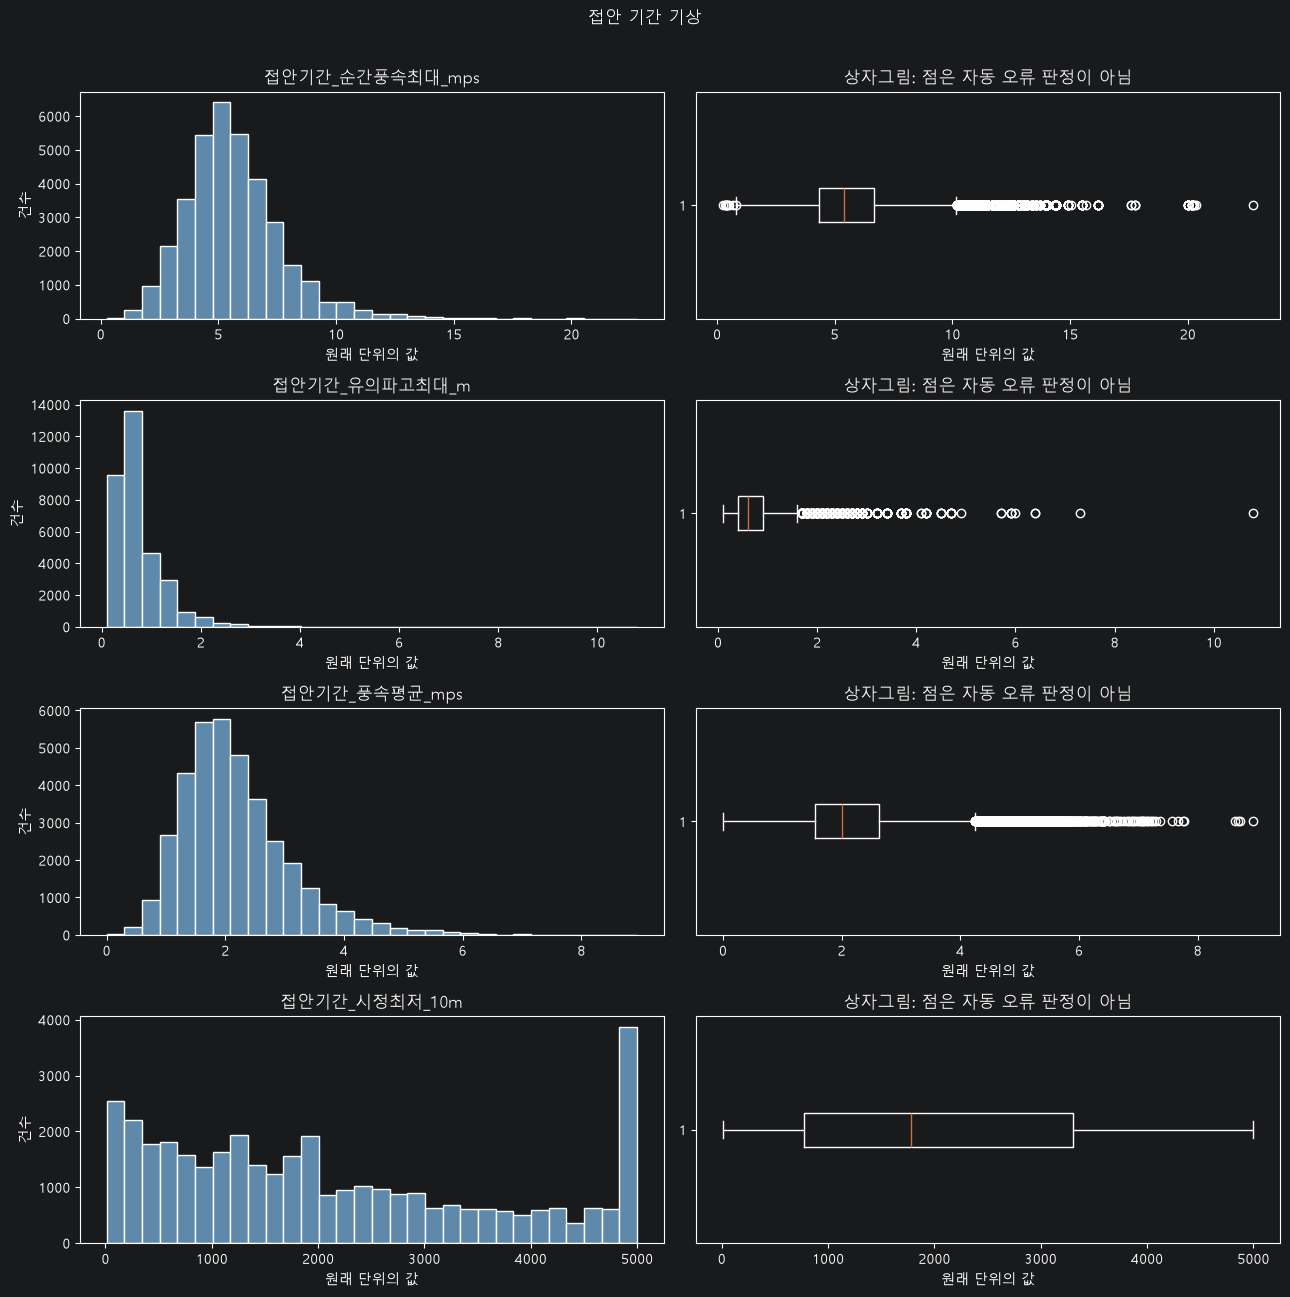

In [18]:
묶음그래프(5, '접안 기간 기상', 묶음5_열)


---

## 6. 입항 시 특보·해구 자료

특보 종류·수준 코드·출처는 범주형, 시작·종료는 날짜형입니다. 해구 수치예측은 관측값과 다릅니다. 출처별 빈도와 결측을 먼저 확인하세요.

### A. 원래 값 미리보기


In [19]:
묶음6_열 = ['입항시_특보종류구성_사건기준', '입항시_특보기간최고수준_사건기준', '입항시_특보시작_KST', '입항시_특보종료_KST', '입항시_해구예측유의파고_m', '입항시_해구예측풍속_mps', '입항시_해구예측풍향_deg', '입항시_해구우선_분석풍속_mps', '입항시_해구우선_분석풍속출처', '입항시_해구우선_분석유의파고_m', '입항시_해구우선_분석유의파고출처']
빠진열 = [열 for 열 in 묶음6_열 if 열 not in 자료.columns]
if 빠진열:
    raise KeyError(f"찾을 수 없는 열: {빠진열}")
display(자료[묶음6_열].head(10))


,입항시_특보종류구성_사건기준,입항시_특보기간최고수준_사건기준,입항시_특보시작_KST,입항시_특보종료_KST,입항시_해구예측유의파고_m,입항시_해구예측풍속_mps,입항시_해구예측풍향_deg,입항시_해구우선_분석풍속_mps,입항시_해구우선_분석풍속출처,입항시_해구우선_분석유의파고_m,입항시_해구우선_분석유의파고출처
0,태풍/풍랑,3.0,2022-09-02 20:00:00,2022-09-06 17:00:00,NaN,NaN,NaN,1.61,기존기상관측,0.9,기존기상관측
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.60,기존기상관측,1.0,기존기상관측
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.05,기존기상관측,0.8,기존기상관측
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.30,기존기상관측,0.6,기존기상관측
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.38,기존기상관측,0.7,기존기상관측
5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.41,기존기상관측,0.5,기존기상관측
6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.44,기존기상관측,0.8,기존기상관측
7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.35,기존기상관측,0.7,기존기상관측
8,풍랑,2.0,2021-08-21 11:00:00,2021-08-22 04:00:00,1.0,9.8,212.0,9.80,해구수치예측(특보중),1.0,해구수치예측(특보중)
9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.77,기존기상관측,0.5,기존기상관측


### B. 결측·이상치 후보·통계

NaN인 통계는 해당 없음 또는 판정 보류입니다. 판정 설명을 함께 확인하세요.


In [20]:
묶음6_통계 = 묶음분석(6, '입항 시 특보·해구 자료', 묶음6_열)


범주별 건수: 입항시_특보종류구성_사건기준


,묶음,열이름,값,건수,비율_pct
0,입항 시 특보·해구 자료,입항시_특보종류구성_사건기준,(원본빈값),34242,92.937792
1,입항 시 특보·해구 자료,입항시_특보종류구성_사건기준,풍랑,2505,6.798936
2,입항 시 특보·해구 자료,입항시_특보종류구성_사건기준,태풍/풍랑,97,0.263272


범주별 건수: 입항시_특보기간최고수준_사건기준


,묶음,열이름,값,건수,비율_pct
0,입항 시 특보·해구 자료,입항시_특보기간최고수준_사건기준,(원본빈값),34242,92.937792
1,입항 시 특보·해구 자료,입항시_특보기간최고수준_사건기준,2.0,2346,6.367387
2,입항 시 특보·해구 자료,입항시_특보기간최고수준_사건기준,3.0,256,0.694821


범주별 건수: 입항시_해구우선_분석풍속출처


,묶음,열이름,값,건수,비율_pct
0,입항 시 특보·해구 자료,입항시_해구우선_분석풍속출처,기존기상관측,33904,92.02041
1,입항 시 특보·해구 자료,입항시_해구우선_분석풍속출처,해구수치예측(특보중),2360,6.405385
2,입항 시 특보·해구 자료,입항시_해구우선_분석풍속출처,결측,580,1.574205


범주별 건수: 입항시_해구우선_분석유의파고출처


,묶음,열이름,값,건수,비율_pct
0,입항 시 특보·해구 자료,입항시_해구우선_분석유의파고출처,기존기상관측,30231,82.051352
1,입항 시 특보·해구 자료,입항시_해구우선_분석유의파고출처,결측,4253,11.543263
2,입항 시 특보·해구 자료,입항시_해구우선_분석유의파고출처,해구수치예측(특보중),2360,6.405385


,열이름,자료형,전체수,유효수,결측치수,결측률_pct,원본빈값수,결측표시문자수,이상치후보수,IQR후보수,물리범위위반수,숫자변환실패수,날짜변환실패수,무한값수,평균,중앙값,P50,P75,P90,P95,최소값,최대값,IQR판정,판정설명,묶음,Q1,IQR,IQR하한,IQR상한,원형평균_deg
0,입항시_특보종류구성_사건기준,범주,36844,2602,34242,92.937792,34242,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,범주: IQR 미적용,평균·백분위수는 해당 없음; 빈도표 사용,입항 시 특보·해구 자료,NaN,NaN,NaN,NaN,NaN
1,입항시_특보기간최고수준_사건기준,범주,36844,2602,34242,92.937792,34242,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,범주: IQR 미적용,평균·백분위수는 해당 없음; 빈도표 사용,입항 시 특보·해구 자료,NaN,NaN,NaN,NaN,NaN
2,입항시_특보시작_KST,날짜,36844,2602,34242,92.937792,34242,0,0.0,NaN,NaN,NaN,0.0,NaN,NaN,2023-01-14 18:00:00,2023-01-14 18:00:00,2024-02-20 11:00:00,2024-07-26 12:00:00,2024-09-28 13:00:00,2020-01-07 18:00:00,2024-12-22 01:00:00,날짜: IQR 미적용,종료가 시작보다 이른 기록을 후보로 표시; 평균은 미계산,입항 시 특보·해구 자료,NaN,NaN,NaN,NaN,NaN
3,입항시_특보종료_KST,날짜,36844,2602,34242,92.937792,34242,0,0.0,NaN,NaN,NaN,0.0,NaN,NaN,2023-01-16 06:00:00,2023-01-16 06:00:00,2024-02-24 12:00:00,2024-07-27 21:00:00,2024-09-29 20:00:00,2020-01-09 06:00:00,2024-12-22 14:00:00,날짜: IQR 미적용,종료가 시작보다 이른 기록을 후보로 표시; 평균은 미계산,입항 시 특보·해구 자료,NaN,NaN,NaN,NaN,NaN
4,입항시_해구예측유의파고_m,숫자,36844,2360,34484,93.594615,34484,0,6.0,6.0,0.0,0.0,NaN,0.0,1.253814,0.8,0.8,2.0,2.7,3.2,0.1,4.7,1.5×IQR 적용,후보는 오류로 확정하지 않으며 자동 삭제하지 않음,입항 시 특보·해구 자료,0.5,1.50,-1.75,4.25,NaN
5,입항시_해구예측풍속_mps,숫자,36844,2360,34484,93.594615,34484,0,10.0,10.0,0.0,0.0,NaN,0.0,9.290636,9.3,9.3,11.4,13.3,14.2,0.5,19.3,1.5×IQR 적용,후보는 오류로 확정하지 않으며 자동 삭제하지 않음,입항 시 특보·해구 자료,7.2,4.20,0.90,17.70,NaN
6,입항시_해구예측풍향_deg,숫자,36844,2360,34484,93.594615,34484,0,0.0,NaN,0.0,0.0,NaN,0.0,124.919915,53.0,53.0,228.25,311.0,332.0,0.0,359.0,풍향 각도: IQR 미적용,후보는 오류로 확정하지 않으며 자동 삭제하지 않음,입항 시 특보·해구 자료,32.0,196.25,NaN,NaN,18.033021
7,입항시_해구우선_분석풍속_mps,숫자,36844,36264,580,1.574205,580,0,2290.0,2290.0,0.0,0.0,NaN,0.0,2.565373,1.92,1.92,3.2,4.83,7.35,0.0,19.3,1.5×IQR 적용,후보는 오류로 확정하지 않으며 자동 삭제하지 않음,입항 시 특보·해구 자료,1.1,2.10,-2.05,6.35,NaN
8,입항시_해구우선_분석풍속출처,범주,36844,36264,580,1.574205,0,580,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,범주: IQR 미적용,평균·백분위수는 해당 없음; 빈도표 사용,입항 시 특보·해구 자료,NaN,NaN,NaN,NaN,NaN
9,입항시_해구우선_분석유의파고_m,숫자,36844,32591,4253,11.543263,4253,0,2290.0,2290.0,0.0,0.0,NaN,0.0,0.522721,0.4,0.4,0.6,0.9,1.2,0.1,4.7,1.5×IQR 적용,후보는 오류로 확정하지 않으며 자동 삭제하지 않음,입항 시 특보·해구 자료,0.3,0.30,-0.15,1.05,NaN


### C. 분포와 빈도 그림

히스토그램은 값이 어느 구간에 모이는지, 상자그림은 중앙과 분포의 꼬리를 보여줍니다.


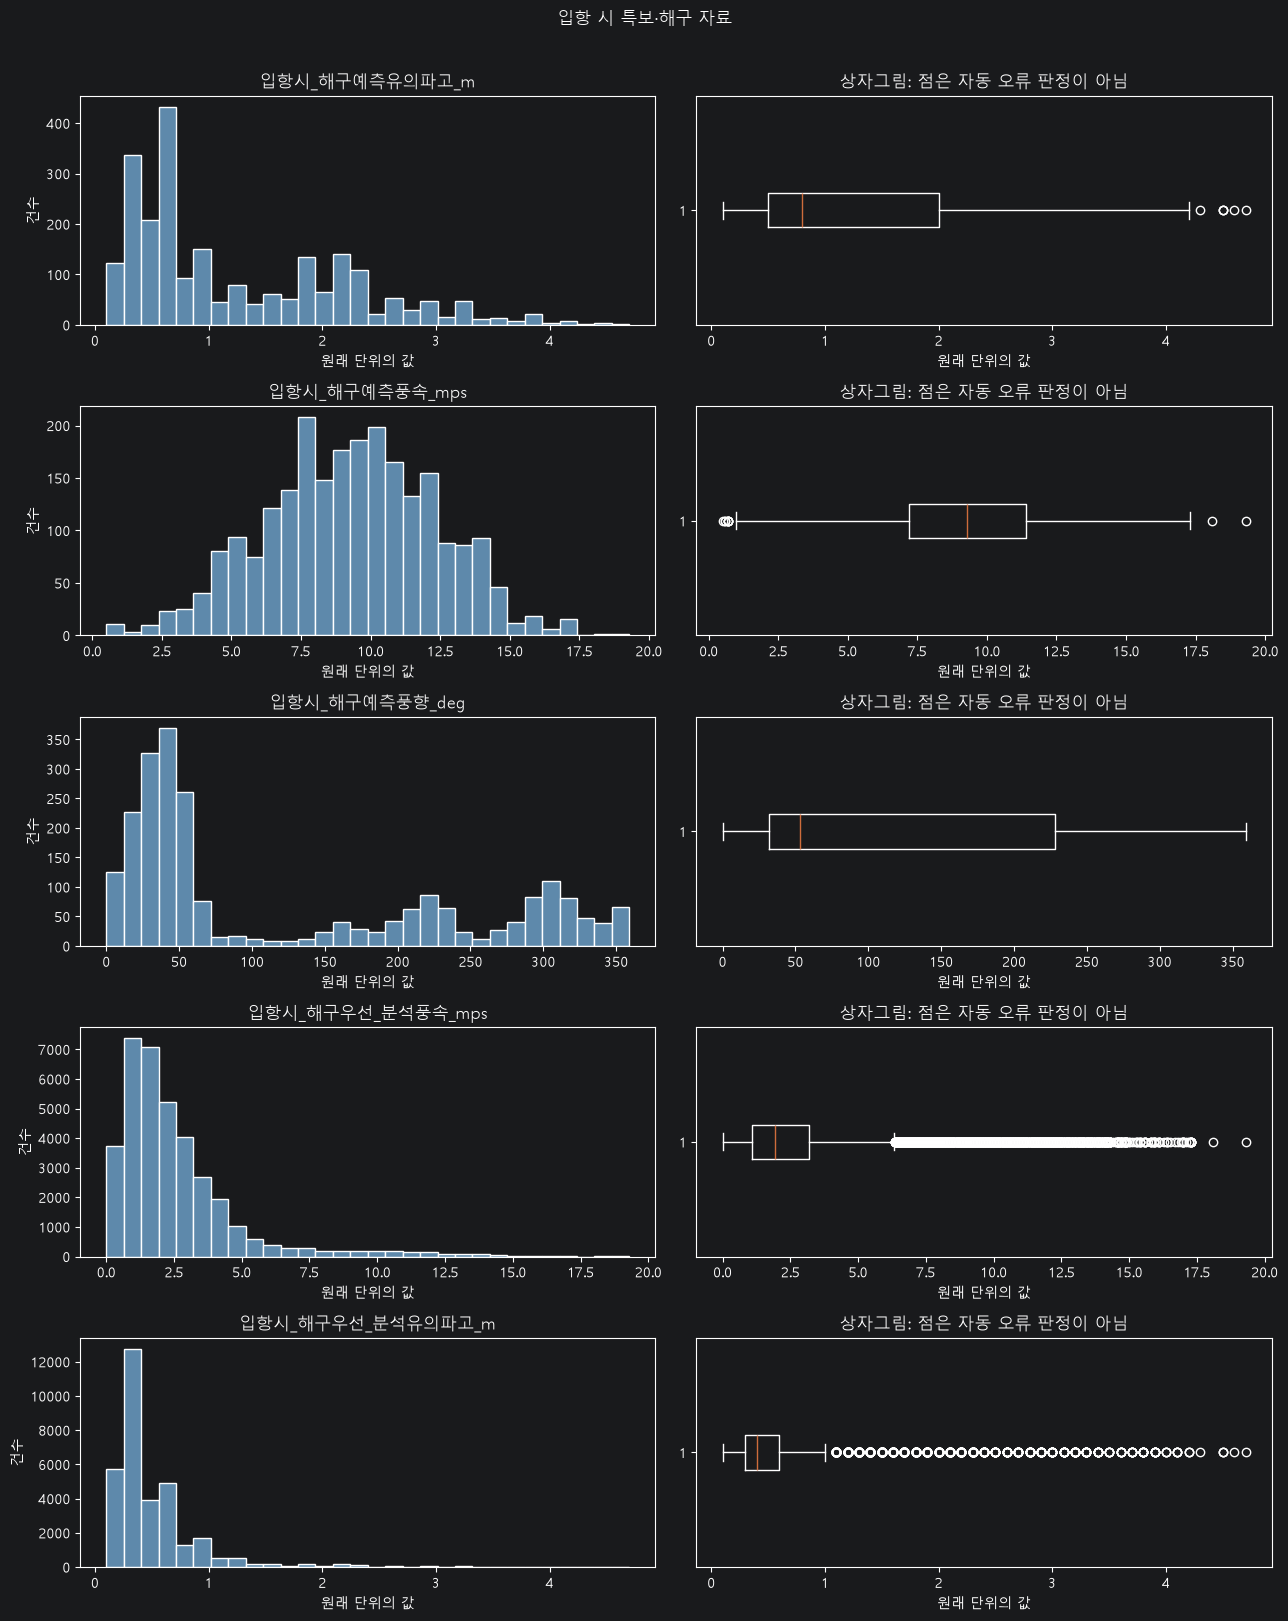

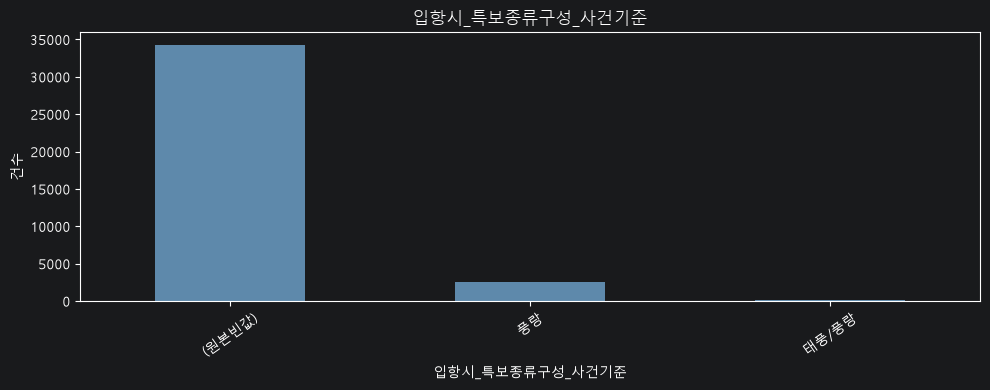

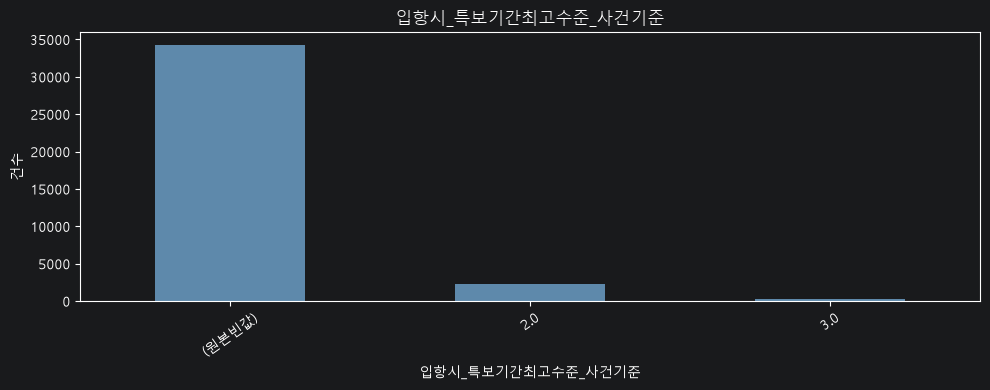

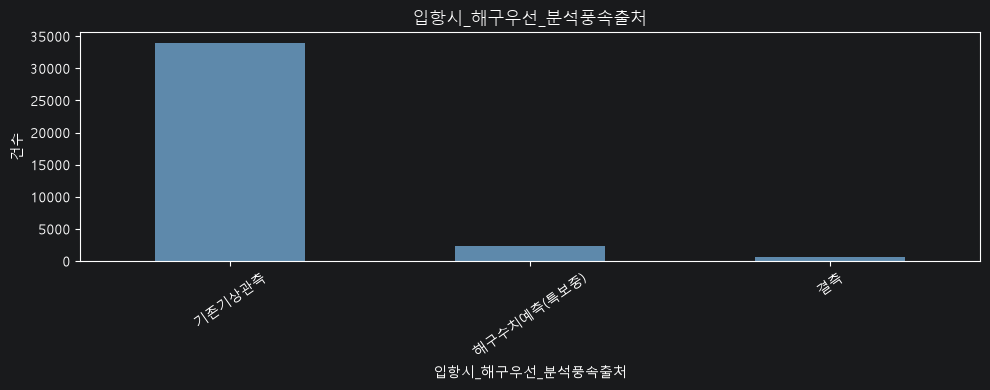

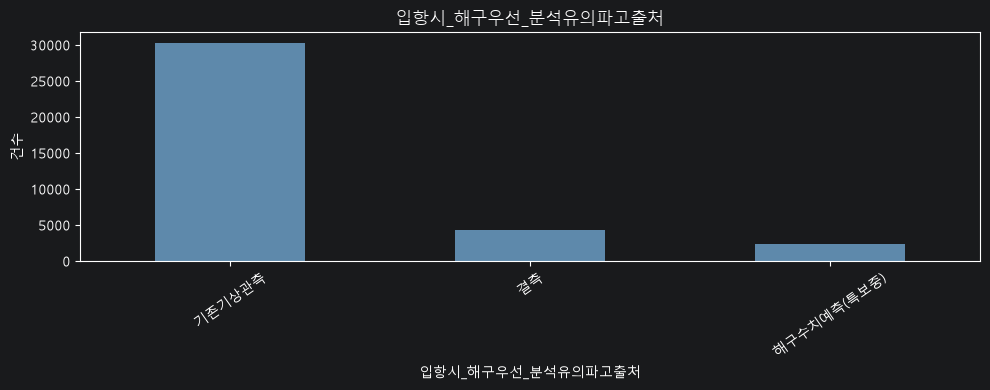

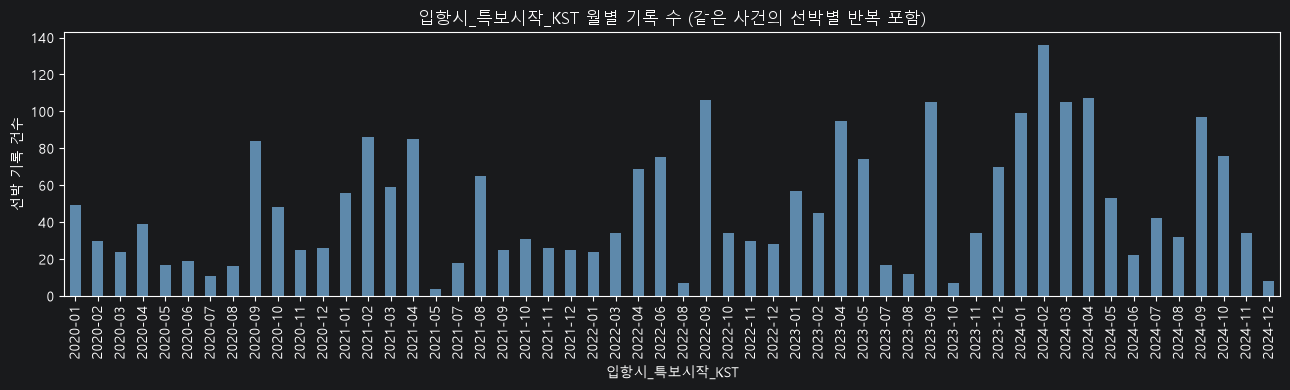

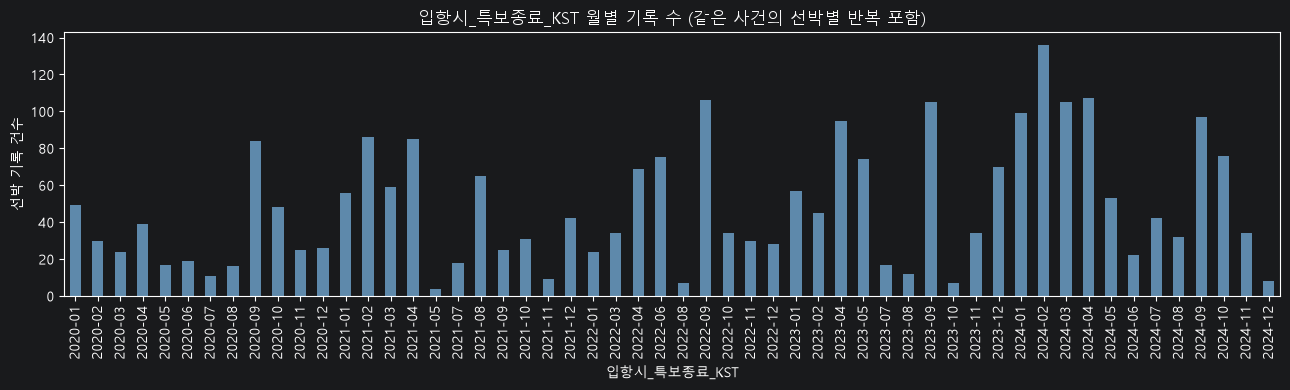

In [21]:
묶음그래프(6, '입항 시 특보·해구 자료', 묶음6_열)


---

## 7. 접안 시 해구 자료

매칭상태의 특보없음과 특보중_예측표본없음은 서로 다른 상황입니다. 모두 예측값이 비어 있을 수 있으므로 상태 빈도표를 함께 봅니다.

### A. 원래 값 미리보기


In [22]:
묶음7_열 = ['접안시_해구예측유의파고_m', '접안시_해구예측풍속_mps', '접안시_해구예측풍향_deg', '접안시_해구예측매칭상태', '접안시_해구우선_분석풍속_mps', '접안시_해구우선_분석풍속출처', '접안시_해구우선_분석유의파고_m', '접안시_해구우선_분석유의파고출처']
빠진열 = [열 for 열 in 묶음7_열 if 열 not in 자료.columns]
if 빠진열:
    raise KeyError(f"찾을 수 없는 열: {빠진열}")
display(자료[묶음7_열].head(10))


,접안시_해구예측유의파고_m,접안시_해구예측풍속_mps,접안시_해구예측풍향_deg,접안시_해구예측매칭상태,접안시_해구우선_분석풍속_mps,접안시_해구우선_분석풍속출처,접안시_해구우선_분석유의파고_m,접안시_해구우선_분석유의파고출처
0,NaN,NaN,NaN,특보중_예측표본없음,1.61,기존기상관측,0.9,기존기상관측
1,NaN,NaN,NaN,특보없음,1.60,기존기상관측,1.0,기존기상관측
2,NaN,NaN,NaN,특보없음,4.05,기존기상관측,0.8,기존기상관측
3,NaN,NaN,NaN,특보없음,1.30,기존기상관측,0.6,기존기상관측
4,NaN,NaN,NaN,특보없음,1.38,기존기상관측,0.7,기존기상관측
5,NaN,NaN,NaN,특보없음,1.41,기존기상관측,0.5,기존기상관측
6,NaN,NaN,NaN,특보없음,0.89,기존기상관측,0.5,기존기상관측
7,NaN,NaN,NaN,특보없음,3.27,기존기상관측,0.5,기존기상관측
8,1.0,9.8,212.0,특보중_모델연결,9.80,해구수치예측(특보중),1.0,해구수치예측(특보중)
9,NaN,NaN,NaN,특보없음,0.77,기존기상관측,0.5,기존기상관측


### B. 결측·이상치 후보·통계

NaN인 통계는 해당 없음 또는 판정 보류입니다. 판정 설명을 함께 확인하세요.


In [23]:
묶음7_통계 = 묶음분석(7, '접안 시 해구 자료', 묶음7_열)


범주별 건수: 접안시_해구예측매칭상태


,묶음,열이름,값,건수,비율_pct
0,접안 시 해구 자료,접안시_해구예측매칭상태,특보없음,34173,92.750516
1,접안 시 해구 자료,접안시_해구예측매칭상태,특보중_모델연결,2427,6.587233
2,접안 시 해구 자료,접안시_해구예측매칭상태,특보중_예측표본없음,244,0.662252


범주별 건수: 접안시_해구우선_분석풍속출처


,묶음,열이름,값,건수,비율_pct
0,접안 시 해구 자료,접안시_해구우선_분석풍속출처,기존기상관측,33858,91.89556
1,접안 시 해구 자료,접안시_해구우선_분석풍속출처,해구수치예측(특보중),2427,6.587233
2,접안 시 해구 자료,접안시_해구우선_분석풍속출처,결측,559,1.517208


범주별 건수: 접안시_해구우선_분석유의파고출처


,묶음,열이름,값,건수,비율_pct
0,접안 시 해구 자료,접안시_해구우선_분석유의파고출처,기존기상관측,30207,81.986212
1,접안 시 해구 자료,접안시_해구우선_분석유의파고출처,결측,4210,11.426555
2,접안 시 해구 자료,접안시_해구우선_분석유의파고출처,해구수치예측(특보중),2427,6.587233


,열이름,자료형,전체수,유효수,결측치수,결측률_pct,원본빈값수,결측표시문자수,이상치후보수,IQR후보수,물리범위위반수,숫자변환실패수,날짜변환실패수,무한값수,평균,중앙값,P50,P75,P90,P95,최소값,최대값,Q1,IQR,IQR하한,IQR상한,IQR판정,판정설명,묶음,원형평균_deg
0,접안시_해구예측유의파고_m,숫자,36844,2427,34417,93.412767,34417,0,7.0,7.0,0.0,0.0,NaN,0.0,1.250762,0.80,0.80,2.0,2.7,3.1,0.1,4.7,0.5,1.5,-1.75,4.25,1.5×IQR 적용,후보는 오류로 확정하지 않으며 자동 삭제하지 않음,접안 시 해구 자료,NaN
1,접안시_해구예측풍속_mps,숫자,36844,2427,34417,93.412767,34417,0,12.0,12.0,0.0,0.0,NaN,0.0,9.355954,9.40,9.40,11.5,13.3,14.2,0.5,19.3,7.3,4.2,1.00,17.80,1.5×IQR 적용,후보는 오류로 확정하지 않으며 자동 삭제하지 않음,접안 시 해구 자료,NaN
2,접안시_해구예측풍향_deg,숫자,36844,2427,34417,93.412767,34417,0,0.0,NaN,0.0,0.0,NaN,0.0,124.501030,53.00,53.00,228.5,310.0,332.0,0.0,359.0,33.0,195.5,NaN,NaN,풍향 각도: IQR 미적용,후보는 오류로 확정하지 않으며 자동 삭제하지 않음,접안 시 해구 자료,18.480289
3,접안시_해구예측매칭상태,범주,36844,36844,0,0.000000,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,범주: IQR 미적용,평균·백분위수는 해당 없음; 빈도표 사용,접안 시 해구 자료,NaN
4,접안시_해구우선_분석풍속_mps,숫자,36844,36285,559,1.517208,559,0,2356.0,2356.0,0.0,0.0,NaN,0.0,2.574377,1.91,1.91,3.2,4.9,7.5,0.0,19.3,1.1,2.1,-2.05,6.35,1.5×IQR 적용,후보는 오류로 확정하지 않으며 자동 삭제하지 않음,접안 시 해구 자료,NaN
5,접안시_해구우선_분석풍속출처,범주,36844,36285,559,1.517208,0,559,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,범주: IQR 미적용,평균·백분위수는 해당 없음; 빈도표 사용,접안 시 해구 자료,NaN
6,접안시_해구우선_분석유의파고_m,숫자,36844,32634,4210,11.426555,4210,0,2317.0,2317.0,0.0,0.0,NaN,0.0,0.523681,0.40,0.40,0.6,0.9,1.2,0.1,4.7,0.3,0.3,-0.15,1.05,1.5×IQR 적용,후보는 오류로 확정하지 않으며 자동 삭제하지 않음,접안 시 해구 자료,NaN
7,접안시_해구우선_분석유의파고출처,범주,36844,32634,4210,11.426555,0,4210,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,범주: IQR 미적용,평균·백분위수는 해당 없음; 빈도표 사용,접안 시 해구 자료,NaN


### C. 분포와 빈도 그림

히스토그램은 값이 어느 구간에 모이는지, 상자그림은 중앙과 분포의 꼬리를 보여줍니다.


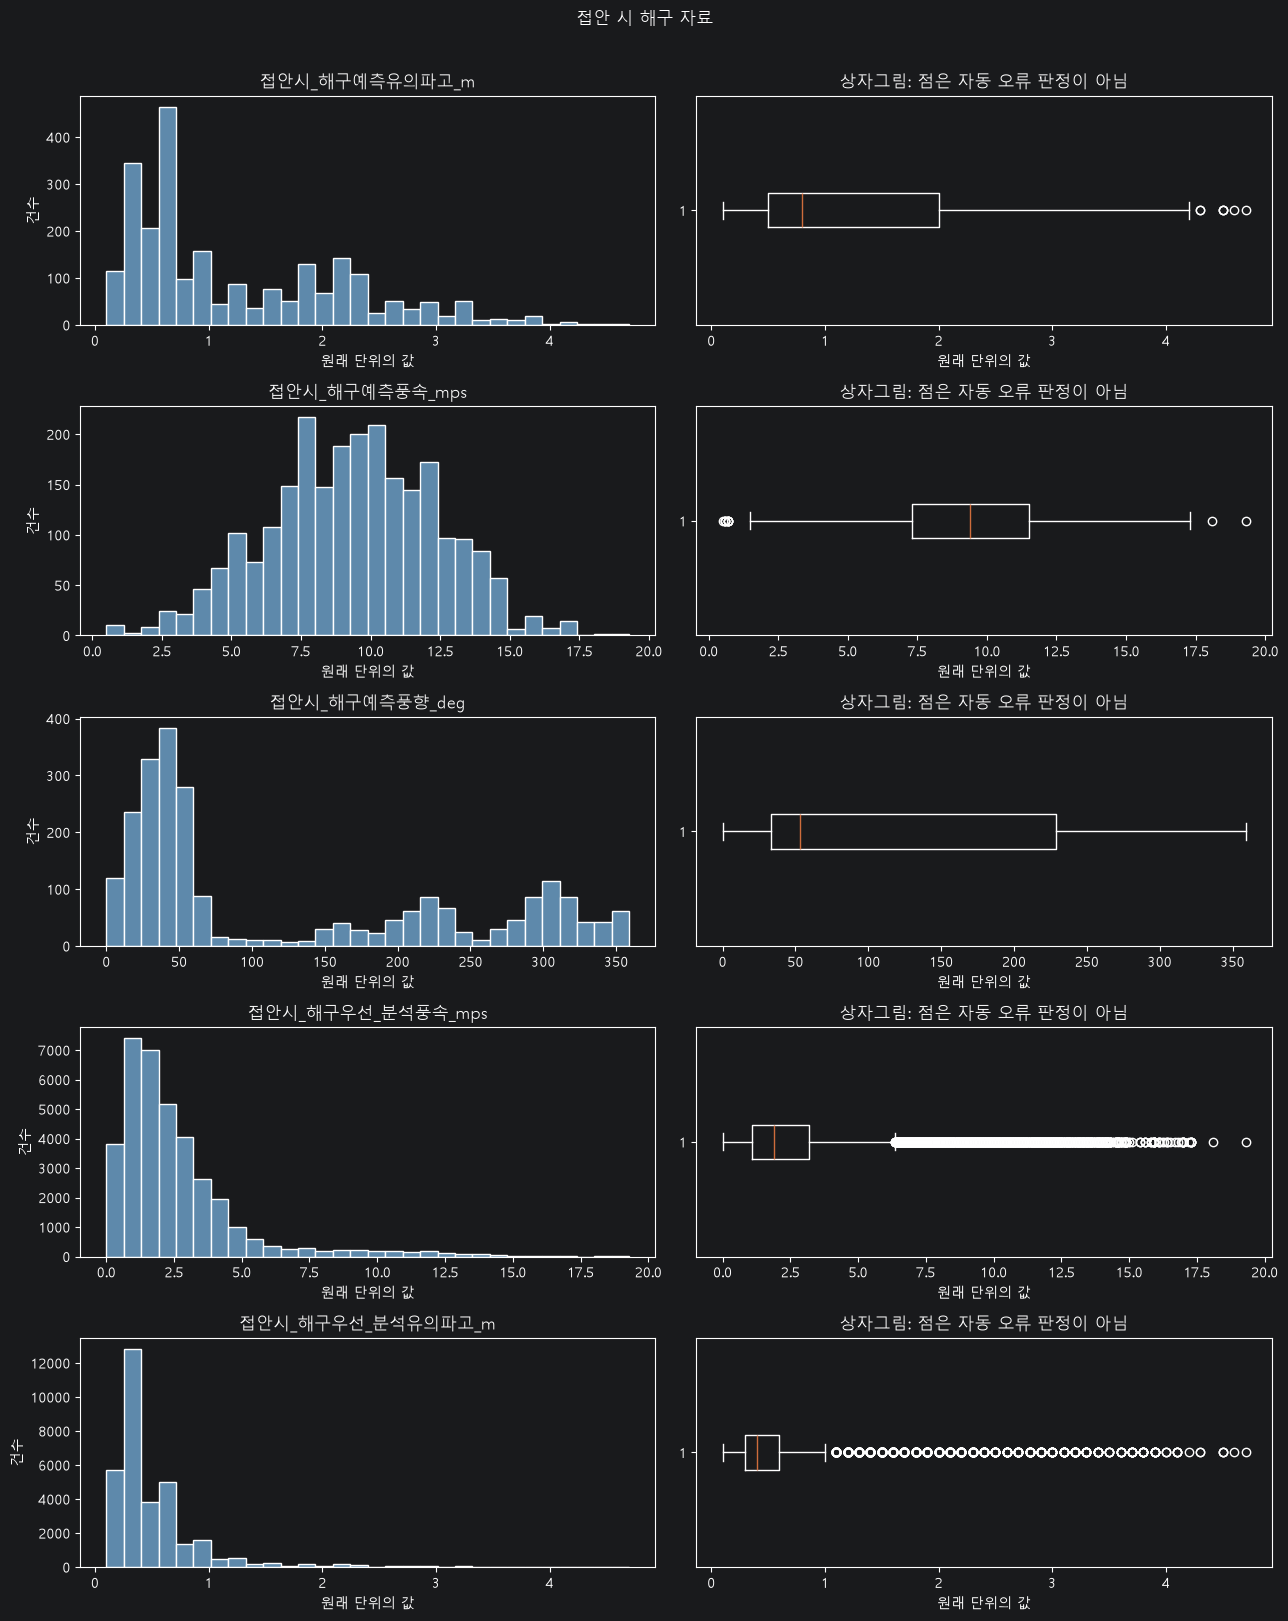

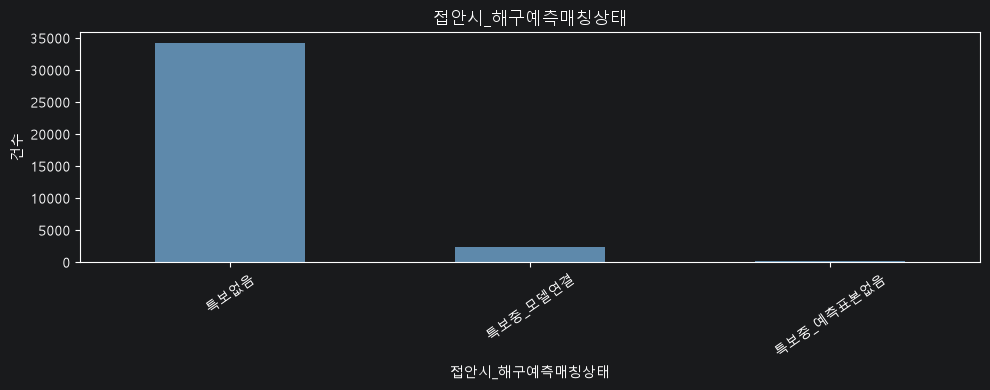

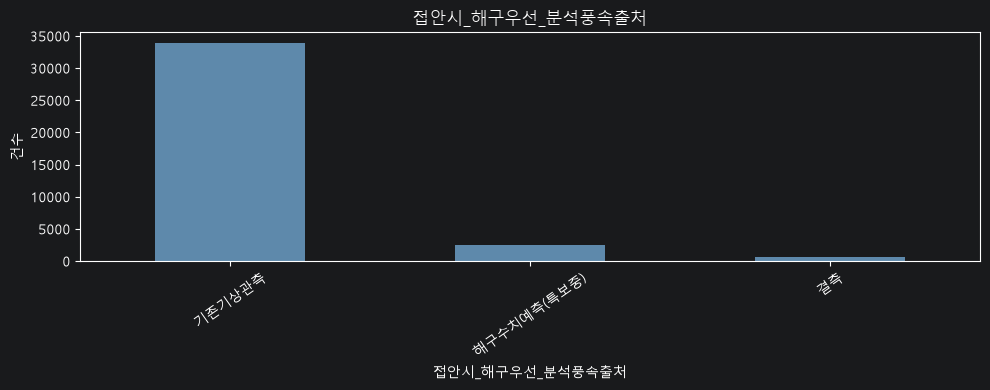

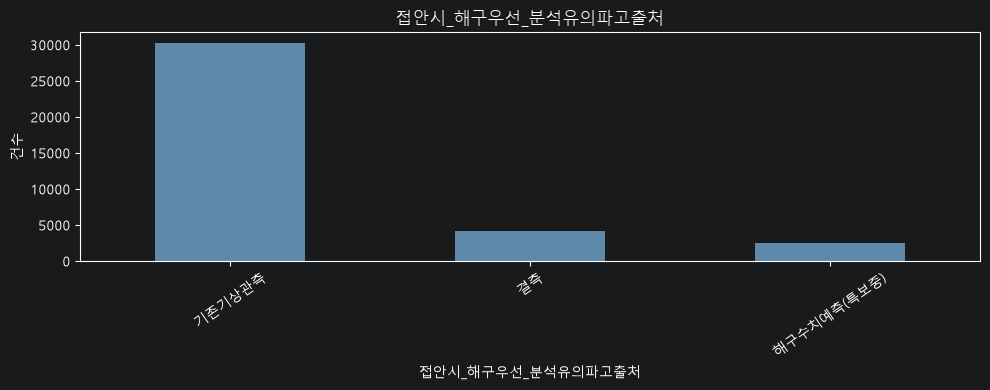

In [24]:
묶음그래프(7, '접안 시 해구 자료', 묶음7_열)


---

## 8. 입항 전 24시간 특보 노출

값이 0인 것은 실제 노출이 없다는 뜻이고 결측과 다릅니다. 가능한 물리 범위는 0~24시간입니다.

### A. 원래 값 미리보기


In [25]:
묶음8_열 = ['입항전24h_특보노출시간_h']
빠진열 = [열 for 열 in 묶음8_열 if 열 not in 자료.columns]
if 빠진열:
    raise KeyError(f"찾을 수 없는 열: {빠진열}")
display(자료[묶음8_열].head(10))


,입항전24h_특보노출시간_h
0,0.366667
1,0.000000
2,0.000000
3,0.000000
4,17.000000
5,9.000000
6,0.000000
7,0.000000
8,10.000000
9,17.000000


### B. 결측·이상치 후보·통계

NaN인 통계는 해당 없음 또는 판정 보류입니다. 판정 설명을 함께 확인하세요.


In [26]:
묶음8_통계 = 묶음분석(8, '입항 전 24시간 특보 노출', 묶음8_열)


,열이름,자료형,전체수,유효수,결측치수,결측률_pct,원본빈값수,결측표시문자수,이상치후보수,IQR후보수,물리범위위반수,숫자변환실패수,날짜변환실패수,무한값수,평균,중앙값,P50,P75,P90,P95,최소값,최대값,Q1,IQR,IQR하한,IQR상한,IQR판정,판정설명,묶음
0,입항전24h_특보노출시간_h,숫자,36844,36844,0,0.0,0,0,NaN,NaN,0,0,NaN,0,1.928594,0.0,0.0,0.0,8.416667,16.166667,0.0,24.0,0.0,0.0,NaN,NaN,표본 4개 미만 또는 IQR=0: 판정 보류,후보는 오류로 확정하지 않으며 자동 삭제하지 않음,입항 전 24시간 특보 노출


### C. 분포와 빈도 그림

히스토그램은 값이 어느 구간에 모이는지, 상자그림은 중앙과 분포의 꼬리를 보여줍니다.


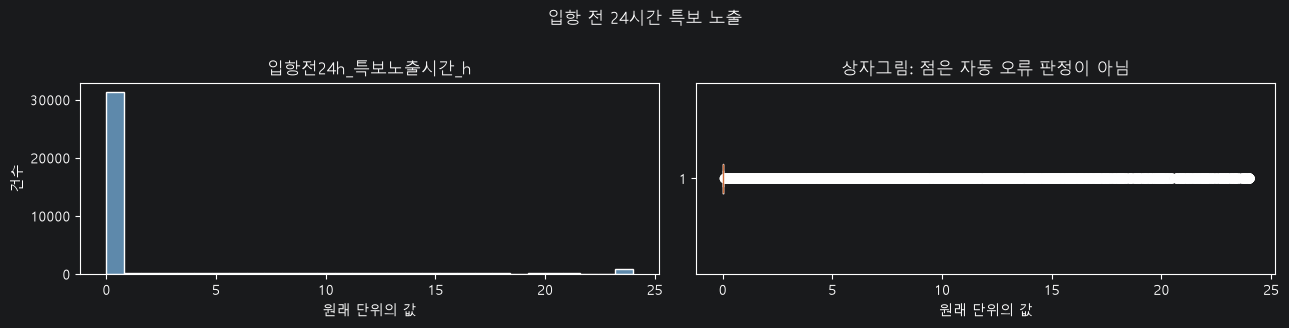

In [27]:
묶음그래프(8, '입항 전 24시간 특보 노출', 묶음8_열)


---

## 9. 접안 전 24시간 특보 노출

가능한 물리 범위는 0~24시간입니다. 0이 많은 경우 IQR=0이 되어 이상치 판정을 보류할 수 있습니다.

### A. 원래 값 미리보기


In [28]:
묶음9_열 = ['접안전24h_특보노출시간_h']
빠진열 = [열 for 열 in 묶음9_열 if 열 not in 자료.columns]
if 빠진열:
    raise KeyError(f"찾을 수 없는 열: {빠진열}")
display(자료[묶음9_열].head(10))


,접안전24h_특보노출시간_h
0,0.583333
1,0.000000
2,0.000000
3,0.000000
4,17.000000
5,8.950000
6,3.883333
7,10.916667
8,10.500000
9,17.000000


### B. 결측·이상치 후보·통계

NaN인 통계는 해당 없음 또는 판정 보류입니다. 판정 설명을 함께 확인하세요.


In [29]:
묶음9_통계 = 묶음분석(9, '접안 전 24시간 특보 노출', 묶음9_열)


,열이름,자료형,전체수,유효수,결측치수,결측률_pct,원본빈값수,결측표시문자수,이상치후보수,IQR후보수,물리범위위반수,숫자변환실패수,날짜변환실패수,무한값수,평균,중앙값,P50,P75,P90,P95,최소값,최대값,Q1,IQR,IQR하한,IQR상한,IQR판정,판정설명,묶음
0,접안전24h_특보노출시간_h,숫자,36844,36844,0,0.0,0,0,NaN,NaN,0,0,NaN,0,1.927955,0.0,0.0,0.0,8.261667,16.195,0.0,24.0,0.0,0.0,NaN,NaN,표본 4개 미만 또는 IQR=0: 판정 보류,후보는 오류로 확정하지 않으며 자동 삭제하지 않음,접안 전 24시간 특보 노출


### C. 분포와 빈도 그림

히스토그램은 값이 어느 구간에 모이는지, 상자그림은 중앙과 분포의 꼬리를 보여줍니다.


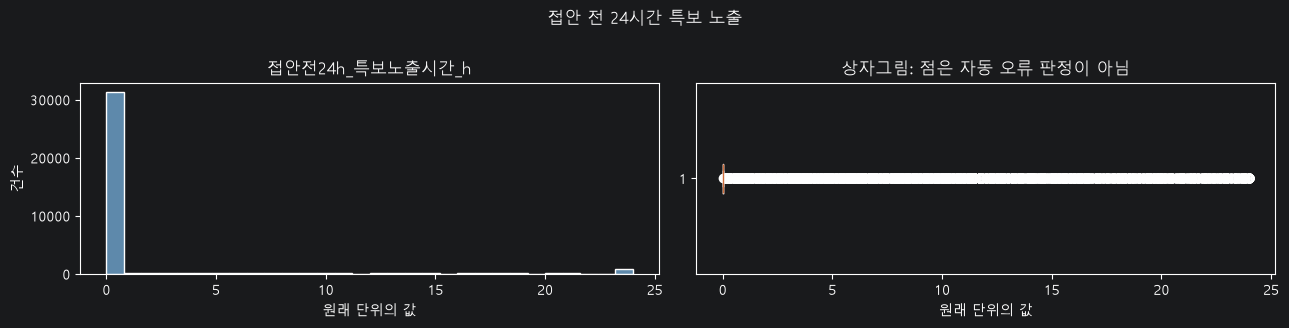

In [30]:
묶음그래프(9, '접안 전 24시간 특보 노출', 묶음9_열)


---

## 10. 입항부터 접안까지 특보 노출

24시간으로 제한된 지표가 아닙니다. 24시간을 넘었다는 이유만으로 오류로 보지 않고, 입항부터 접안까지 실제 시간보다 큰지만 점검합니다. 음수 대기시간과 관련된 결측 가능성도 원본 날짜를 함께 확인하세요.

### A. 원래 값 미리보기


In [31]:
묶음10_열 = ['입항부터접안_특보노출시간_h']
빠진열 = [열 for 열 in 묶음10_열 if 열 not in 자료.columns]
if 빠진열:
    raise KeyError(f"찾을 수 없는 열: {빠진열}")
display(자료[묶음10_열].head(10))


,입항부터접안_특보노출시간_h
0,0.216667
1,NaN
2,0.000000
3,0.000000
4,0.000000
5,0.000000
6,17.000000
7,17.000000
8,0.500000
9,0.000000


### B. 결측·이상치 후보·통계

NaN인 통계는 해당 없음 또는 판정 보류입니다. 판정 설명을 함께 확인하세요.


In [32]:
묶음10_통계 = 묶음분석(10, '입항부터 접안까지 특보 노출', 묶음10_열)


,열이름,자료형,전체수,유효수,결측치수,결측률_pct,원본빈값수,결측표시문자수,이상치후보수,IQR후보수,물리범위위반수,숫자변환실패수,날짜변환실패수,무한값수,평균,중앙값,P50,P75,P90,P95,최소값,최대값,Q1,IQR,IQR하한,IQR상한,IQR판정,판정설명,묶음
0,입항부터접안_특보노출시간_h,숫자,36844,33800,3044,8.261861,3044,0,NaN,NaN,0,0,NaN,0,0.478697,0.0,0.0,0.0,0.0,0.283333,0.0,271.5,0.0,0.0,NaN,NaN,표본 4개 미만 또는 IQR=0: 판정 보류,후보는 오류로 확정하지 않으며 자동 삭제하지 않음,입항부터 접안까지 특보 노출


### C. 분포와 빈도 그림

히스토그램은 값이 어느 구간에 모이는지, 상자그림은 중앙과 분포의 꼬리를 보여줍니다.


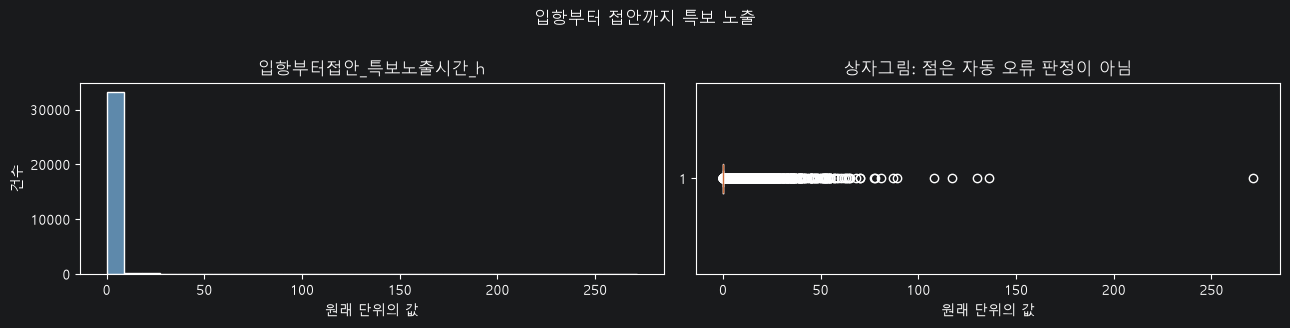

In [33]:
묶음그래프(10, '입항부터 접안까지 특보 노출', 묶음10_열)


---

## 마지막. 전체 결과 합치기

10개 묶음을 실행한 뒤 실행하세요. 통합 요약·범주 빈도·이상치 후보의 원본 행 번호를 저장합니다.


In [34]:
# 같은 셀을 여러 번 실행해도 최종 파일에는 열별 결과가 한 번만 들어가도록 정리합니다.
통합요약 = pd.DataFrame(전체요약).drop_duplicates(["묶음", "열이름"], keep="last")
빈도통합 = pd.concat(전체빈도, ignore_index=True) if 전체빈도 else pd.DataFrame(columns=["묶음", "열이름", "값", "건수", "비율_pct"])
빈도통합 = 빈도통합.drop_duplicates(["묶음", "열이름", "값"], keep="last")
후보통합 = pd.concat(전체후보, ignore_index=True) if 전체후보 else pd.DataFrame(columns=["CSV행번호", "묶음", "열이름", "원래값", "IQR후보", "물리범위위반", "판정설명"])
후보통합 = 후보통합.drop_duplicates(["CSV행번호", "묶음", "열이름"], keep="last")
통합요약.to_csv(저장폴더 / "전체_48열_요약.csv", index=False, encoding="utf-8-sig")
빈도통합.to_csv(저장폴더 / "전체_범주별빈도.csv", index=False, encoding="utf-8-sig")
후보통합.to_csv(저장폴더 / "전체_이상치후보_원본행번호.csv", index=False, encoding="utf-8-sig")
print("분석한 열:", len(통합요약))
print("후보가 있는 서로 다른 CSV 행:", 후보통합["CSV행번호"].nunique())
print("행번호는 일반적인 한 줄당 한 기록 CSV의 헤더 포함 행번호입니다.")
print("저장 위치:", 저장폴더)
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(통합요약)


분석한 열: 48
후보가 있는 서로 다른 CSV 행: 8066
행번호는 일반적인 한 줄당 한 기록 CSV의 헤더 포함 행번호입니다.
저장 위치: C:\work\Port_Cast_Final\2.Data_Integrated Preprocessing\Output\CSV_기상_EDA_결과


,자료형,전체수,원본빈값수,결측표시문자수,결측치수,숫자변환실패수,무한값수,유효수,평균,중앙값,P50,P75,P90,P95,최소값,최대값,물리범위위반수,Q1,IQR,IQR하한,IQR상한,IQR후보수,IQR판정,이상치후보수,판정설명,열이름,묶음,결측률_pct,날짜변환실패수,원형평균_deg
0,숫자,36844,1453,0,1453,0.0,0.0,35391,3.143582,2.82,2.82,4.29,5.67,6.58,0.0,16.19,0.0,1.660000,2.630000,-2.285000,8.235000,467.0,1.5×IQR 적용,467.0,후보는 오류로 확정하지 않으며 자동 삭제하지 않음,입항시_최대순간풍속_mps,입항 시 기상,3.943654,NaN,NaN
1,숫자,36844,4508,0,4508,0.0,0.0,32336,0.504107,0.4,0.4,0.6,0.9,1.1,0.1,4.2,0.0,0.300000,0.300000,-0.150000,1.050000,2210.0,1.5×IQR 적용,2210.0,후보는 오류로 확정하지 않으며 자동 삭제하지 않음,입항시_유의파고_m,입항 시 기상,12.235371,NaN,NaN
2,숫자,36844,4509,0,4509,0.0,0.0,32335,0.688523,0.6,0.6,0.9,1.3,1.6,0.1,6.4,0.0,0.400000,0.500000,-0.350000,1.650000,1363.0,1.5×IQR 적용,1363.0,후보는 오류로 확정하지 않으며 자동 삭제하지 않음,입항시_최대파고_m,입항 시 기상,12.238085,NaN,NaN
3,숫자,36844,605,0,605,0.0,0.0,36239,2.155041,1.88,1.88,2.95,4.1,4.81,0.0,16.2,0.0,1.100000,1.850000,-1.675000,5.725000,796.0,1.5×IQR 적용,796.0,후보는 오류로 확정하지 않으며 자동 삭제하지 않음,입항시_풍속_mps,입항 시 기상,1.642058,NaN,NaN
4,범주,36844,609,0,609,NaN,NaN,36235,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,범주: IQR 미적용,0.0,허용된 8방위 표현 외의 값만 점검 후보,입항시_풍향_8방위,입항 시 기상,1.652915,NaN,NaN
5,숫자,36844,110,0,110,0.0,0.0,36734,3273.777999,3486.5,3486.5,5000.0,5000.0,5000.0,14.0,5000.0,0.0,1919.000000,3081.000000,-2702.500000,9621.500000,0.0,1.5×IQR 적용,0.0,후보는 오류로 확정하지 않으며 자동 삭제하지 않음,입항시_시정_10m,입항 시 기상,0.298556,NaN,NaN
6,숫자,36844,1436,0,1436,0.0,0.0,35408,3.136505,2.82,2.82,4.28,5.63,6.58,0.0,15.03,0.0,1.660000,2.620000,-2.270000,8.210000,473.0,1.5×IQR 적용,473.0,후보는 오류로 확정하지 않으며 자동 삭제하지 않음,접안시_최대순간풍속_mps,접안 시 기상,3.897514,NaN,NaN
7,숫자,36844,4468,0,4468,0.0,0.0,32376,0.504689,0.4,0.4,0.6,0.9,1.2,0.1,4.2,0.0,0.300000,0.300000,-0.150000,1.050000,2238.0,1.5×IQR 적용,2238.0,후보는 오류로 확정하지 않으며 자동 삭제하지 않음,접안시_유의파고_m,접안 시 기상,12.126805,NaN,NaN
8,숫자,36844,4469,0,4469,0.0,0.0,32375,0.689328,0.6,0.6,0.9,1.3,1.6,0.1,6.4,0.0,0.400000,0.500000,-0.350000,1.650000,1364.0,1.5×IQR 적용,1364.0,후보는 오류로 확정하지 않으며 자동 삭제하지 않음,접안시_최대파고_m,접안 시 기상,12.129519,NaN,NaN
9,숫자,36844,579,0,579,0.0,0.0,36265,2.150732,1.87,1.87,2.94,4.1,4.8,0.0,12.23,0.0,1.100000,1.840000,-1.660000,5.700000,828.0,1.5×IQR 적용,828.0,후보는 오류로 확정하지 않으며 자동 삭제하지 않음,접안시_풍속_mps,접안 시 기상,1.571491,NaN,NaN
